FIRST 5 ROWS
  school sex  age address famsize Pstatus  Medu  Fedu     Mjob      Fjob  ...  \
0     GP   F   18       U     GT3       A     4     4  at_home   teacher  ...   
1     GP   F   17       U     GT3       T     1     1  at_home     other  ...   
2     GP   F   15       U     LE3       T     1     1  at_home     other  ...   
3     GP   F   15       U     GT3       T     4     2   health  services  ...   
4     GP   F   16       U     GT3       T     3     3    other     other  ...   

  famrel freetime  goout  Dalc  Walc health absences  G1  G2  G3  
0      4        3      4     1     1      3        6   5   6   6  
1      5        3      3     1     1      3        4   5   5   6  
2      4        3      2     2     3      3       10   7   8  10  
3      3        2      2     1     1      5        2  15  14  15  
4      4        3      2     1     2      5        4   6  10  10  

[5 rows x 33 columns]

LAST 5 ROWS
    school sex  age address famsize Pstatus  Medu  Fedu      M

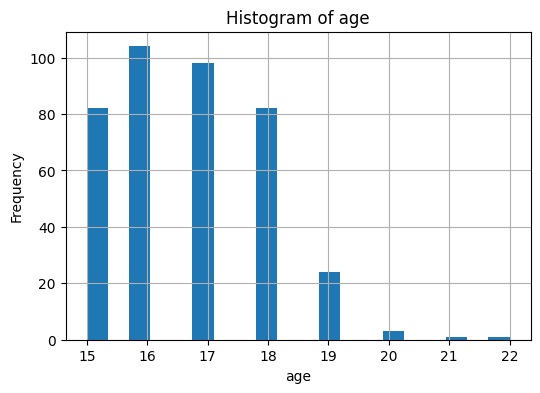

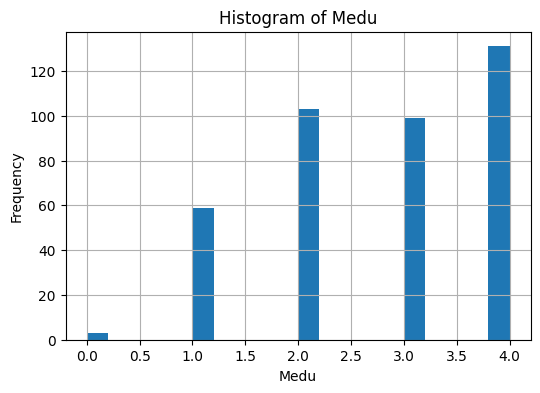

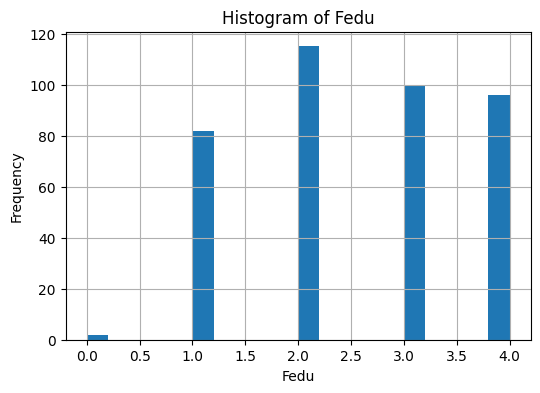

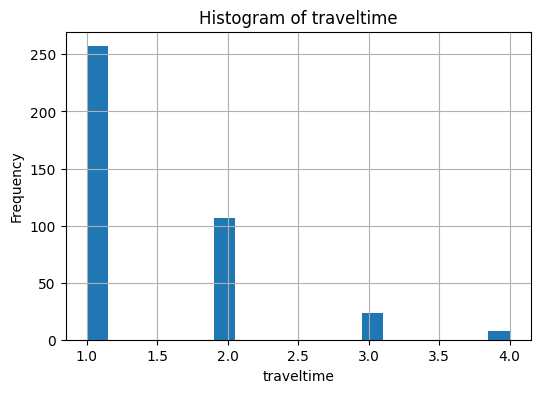

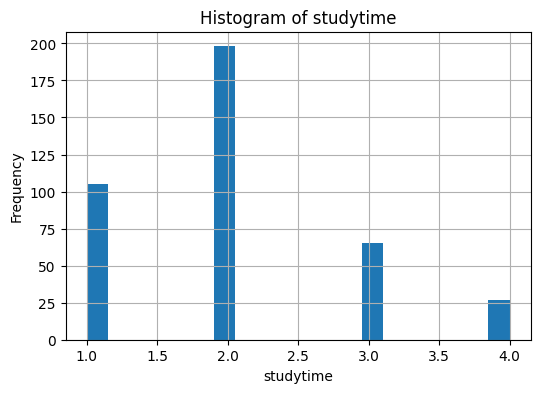

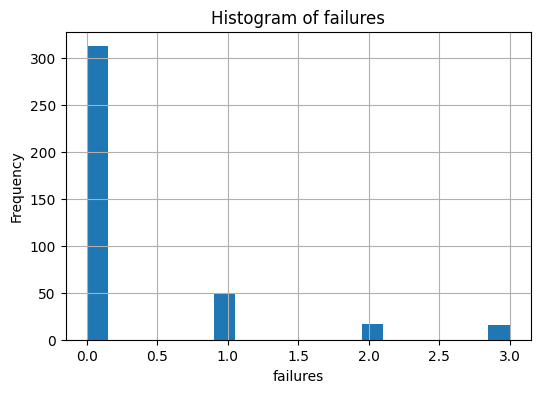

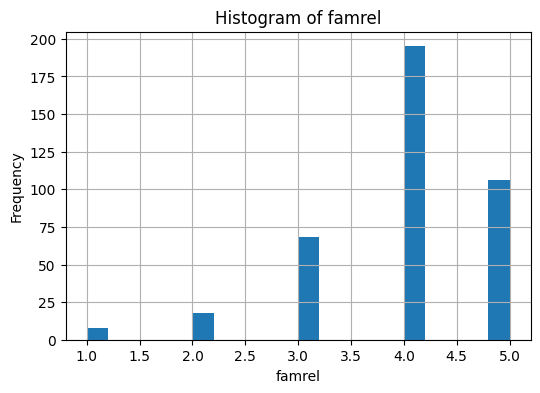

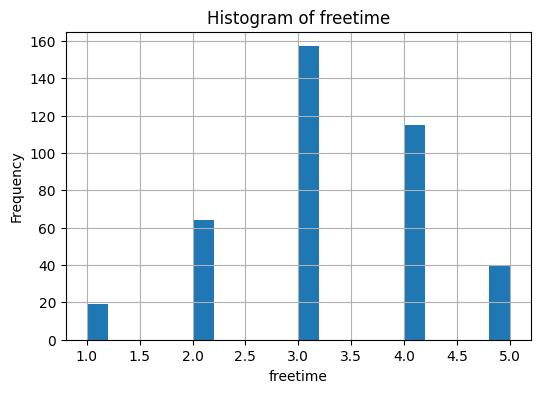

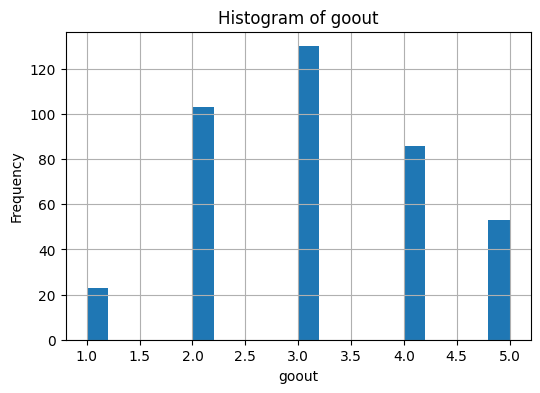

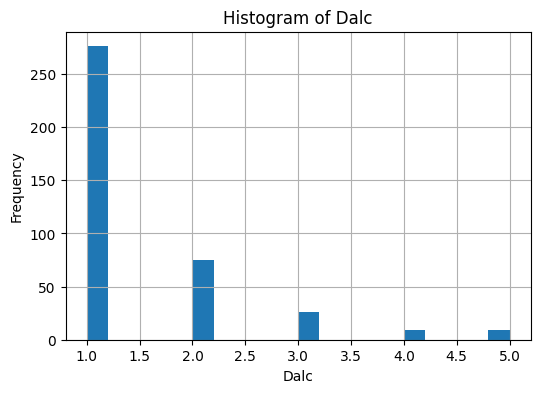

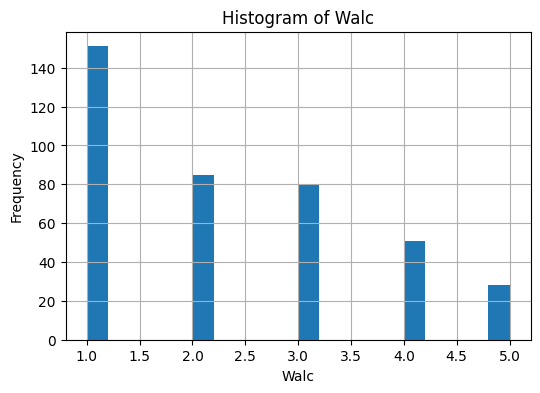

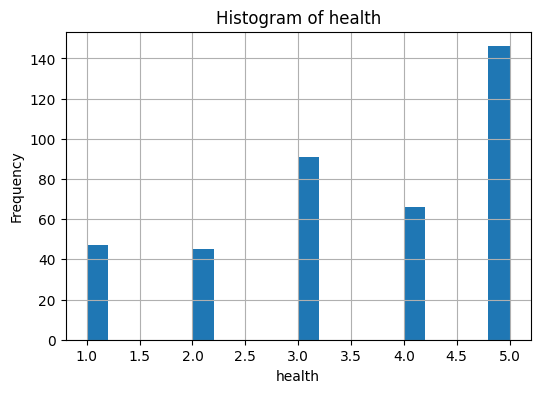

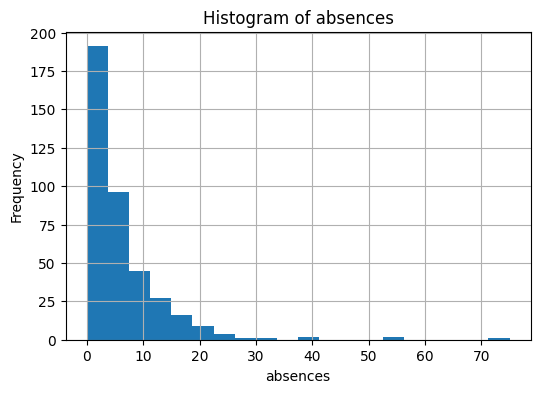

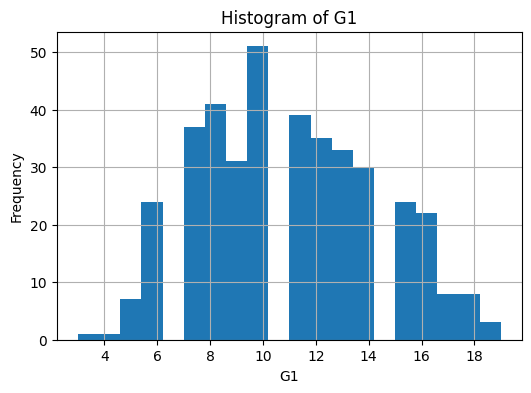

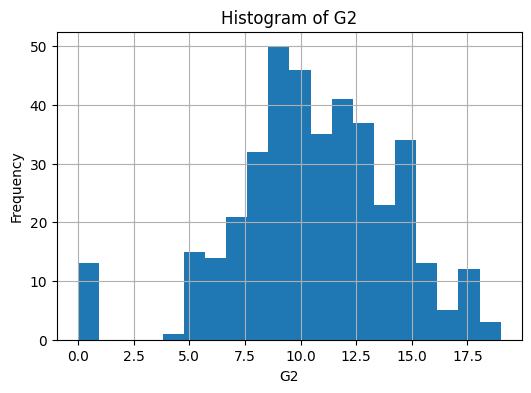

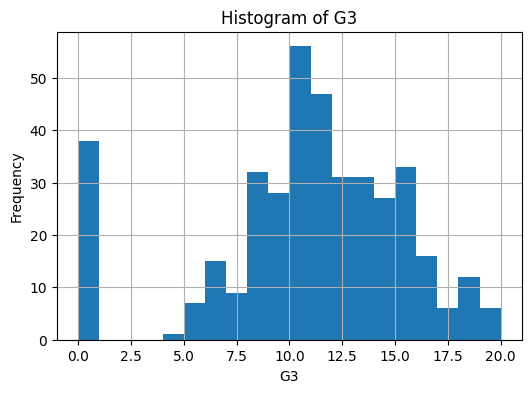

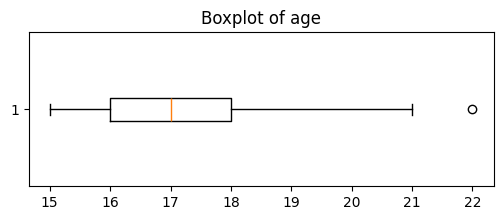

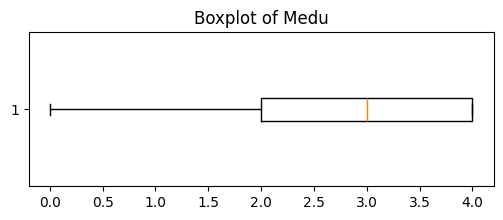

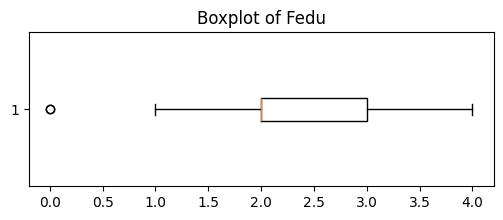

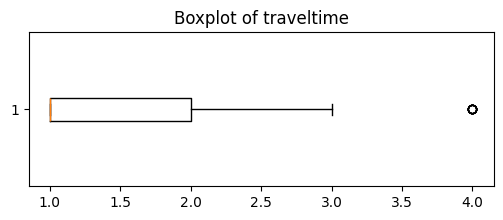

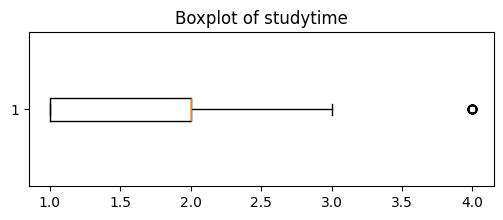

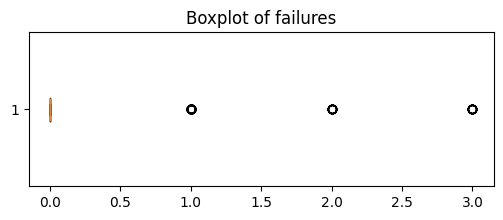

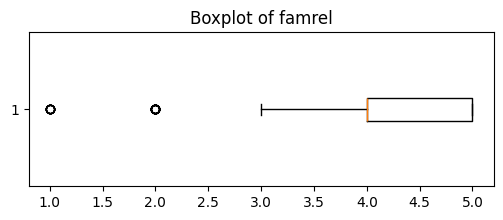

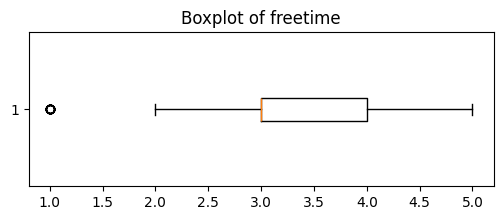

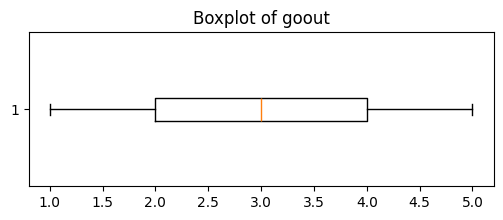

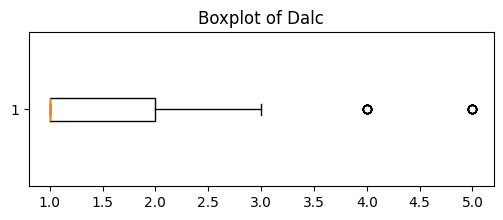

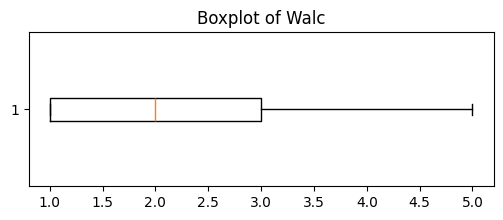

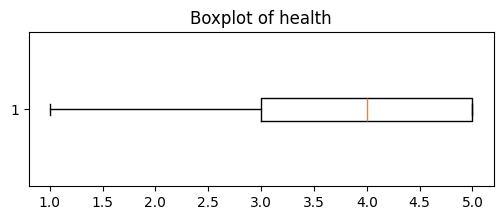

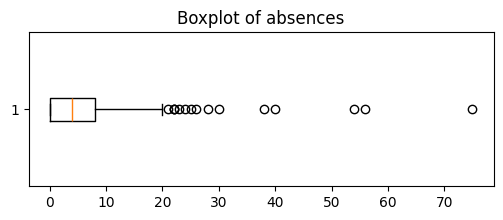

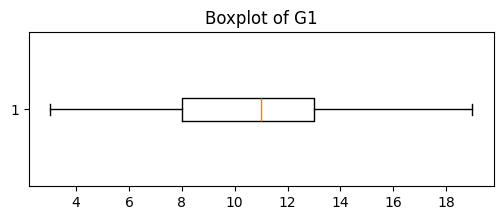

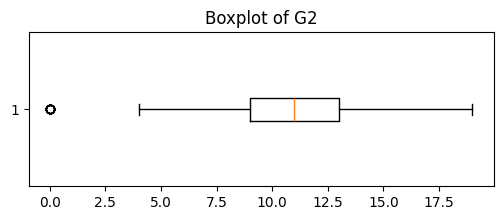

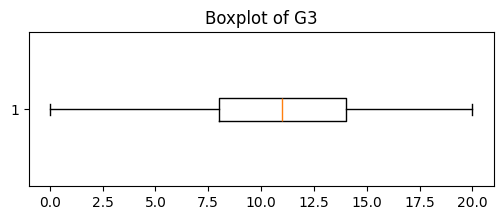

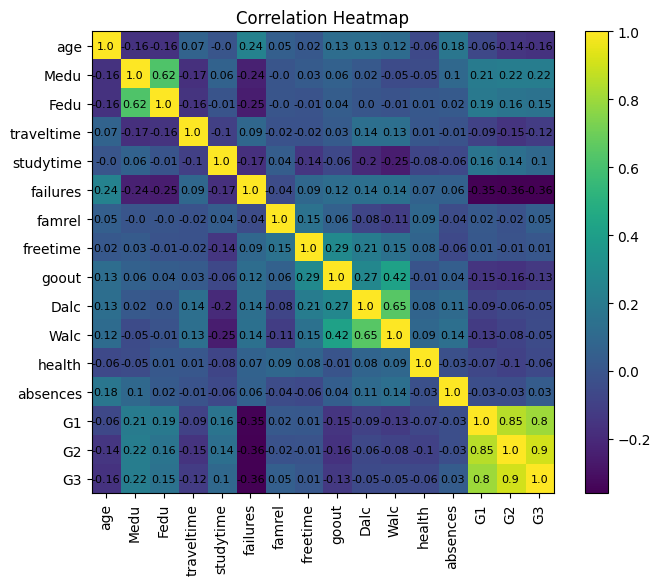

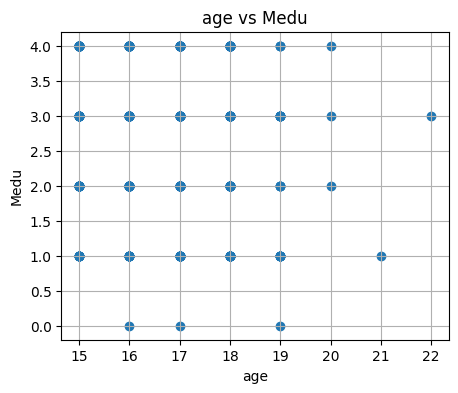

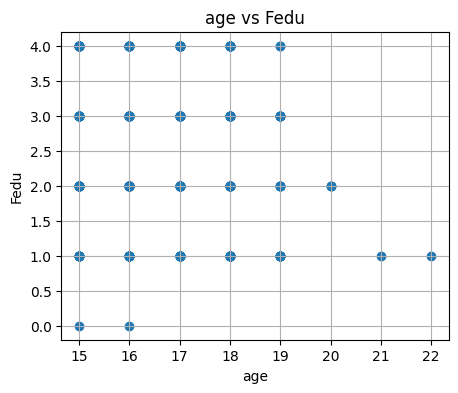

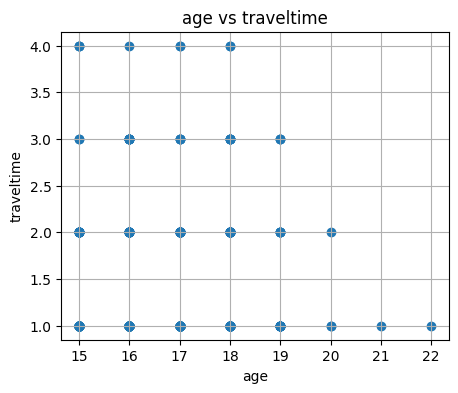

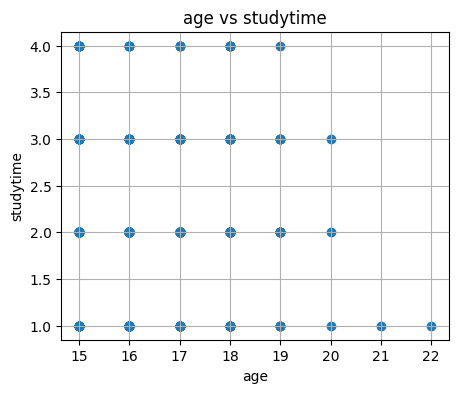

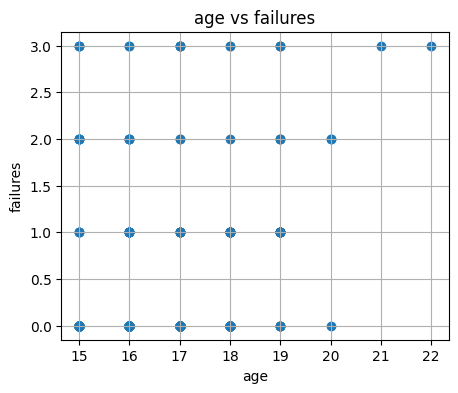

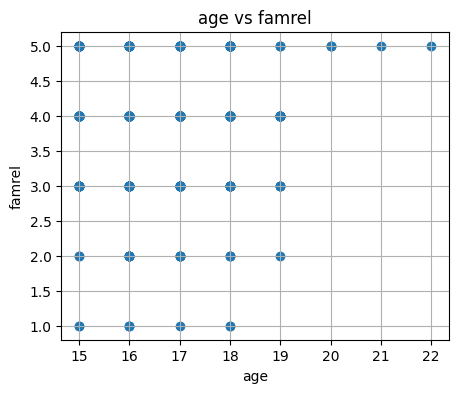

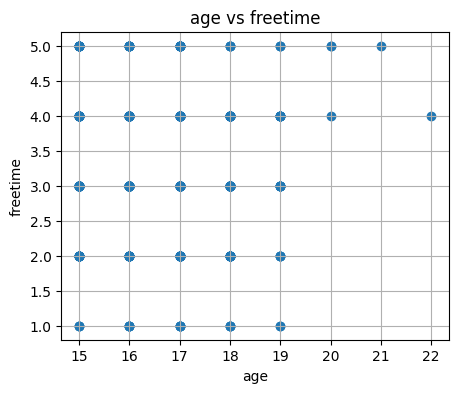

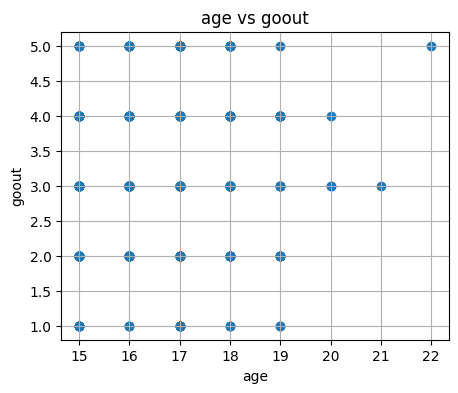

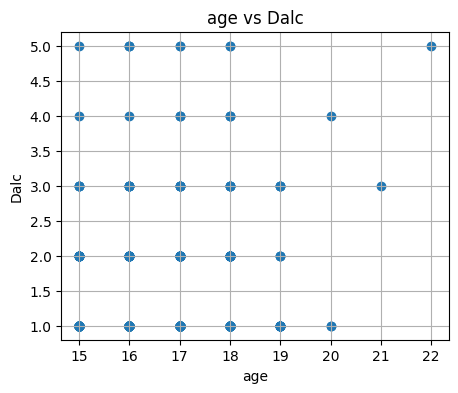

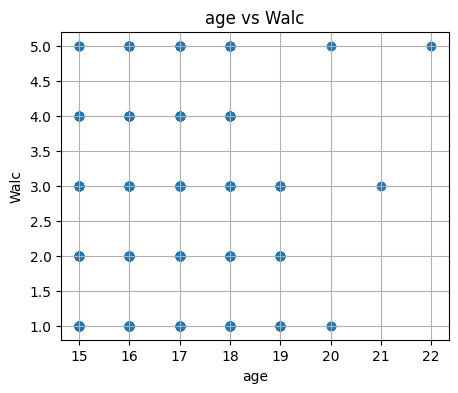

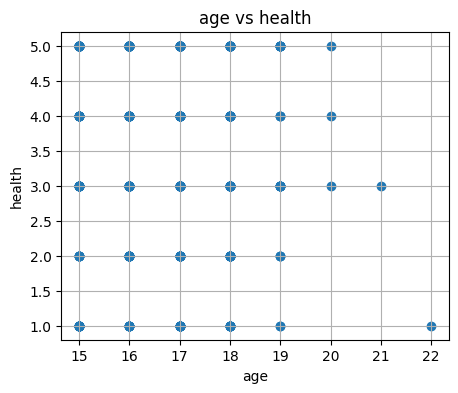

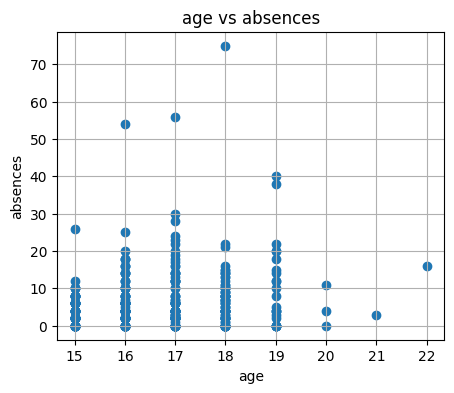

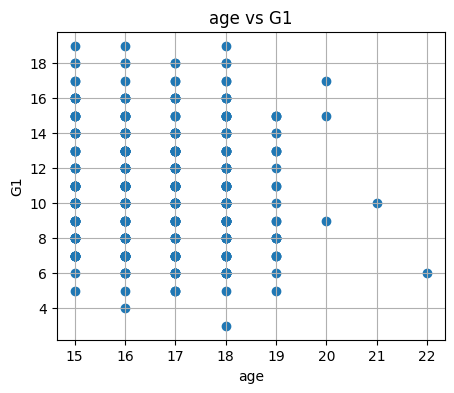

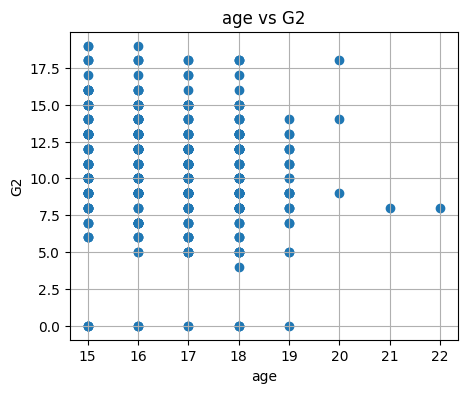

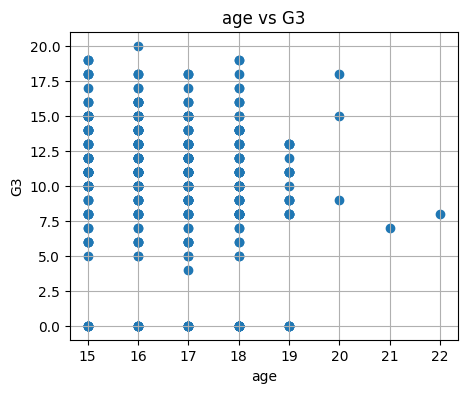

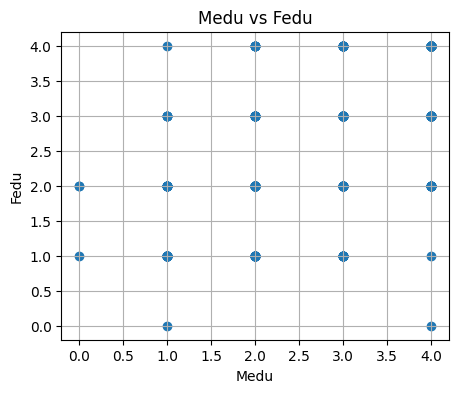

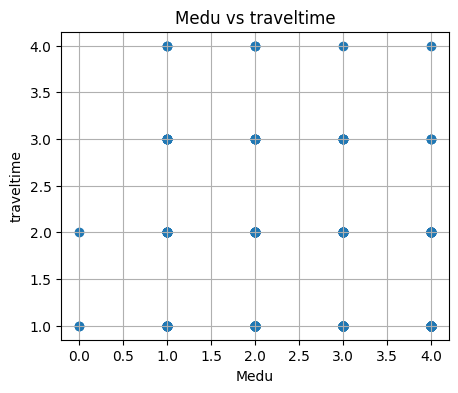

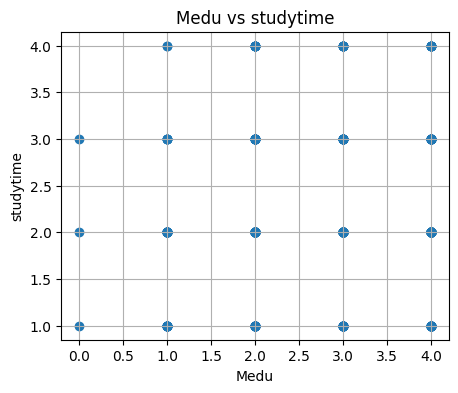

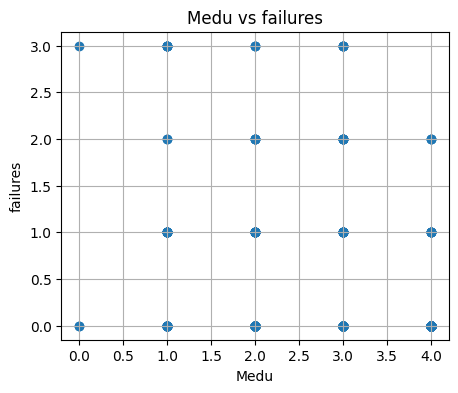

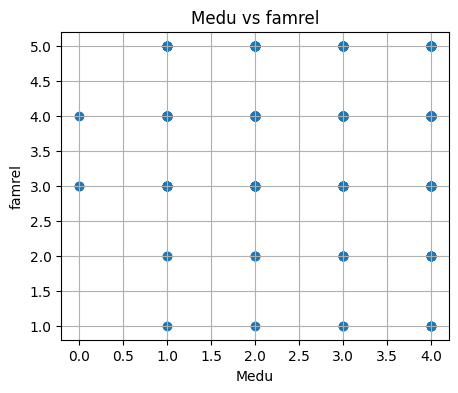

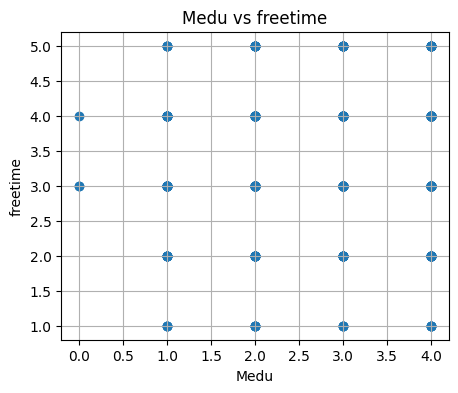

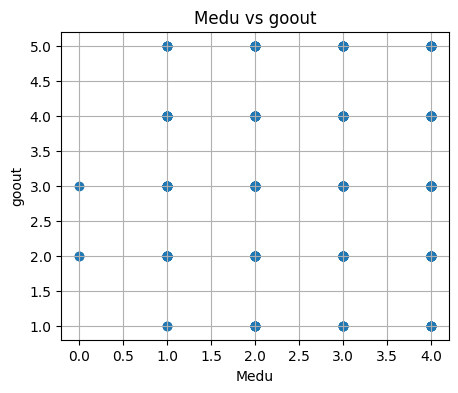

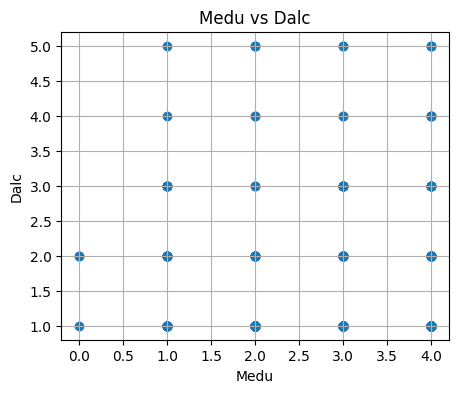

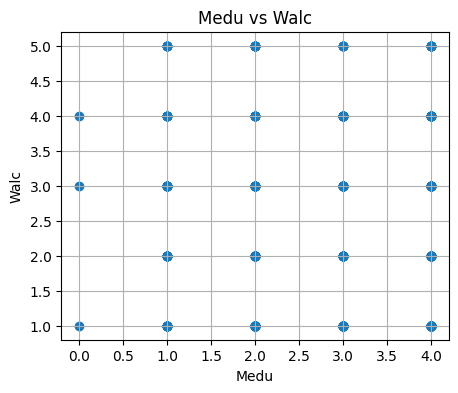

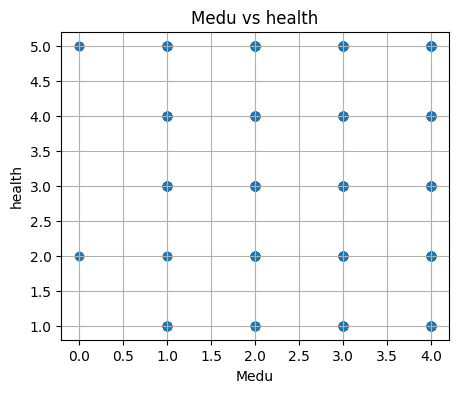

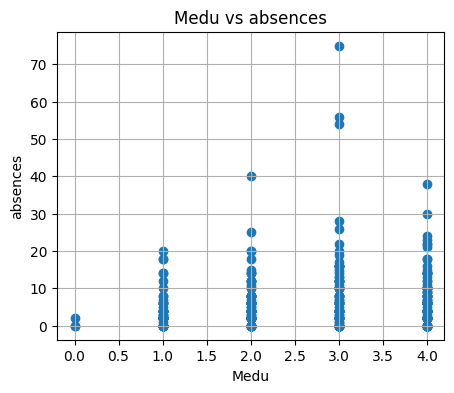

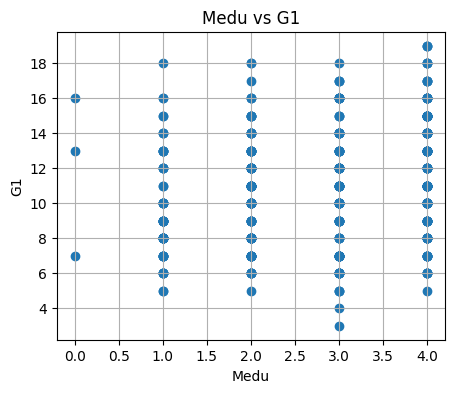

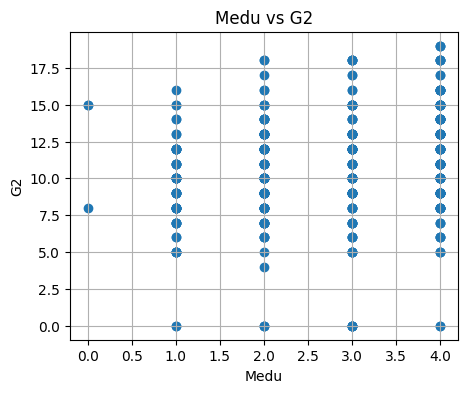

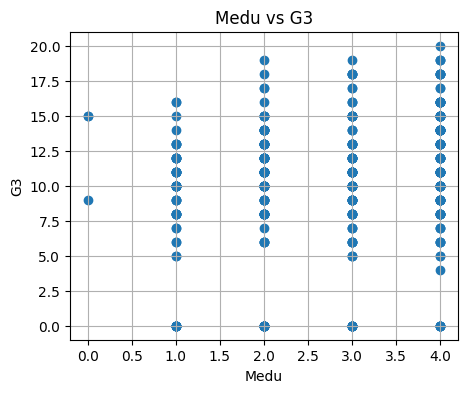

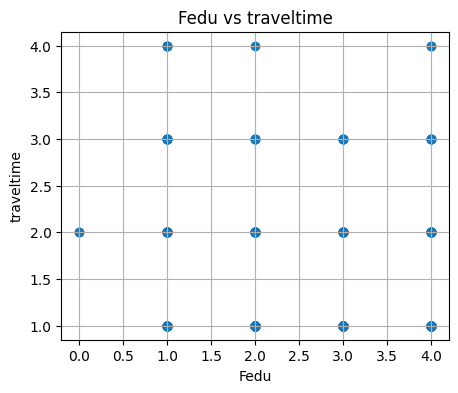

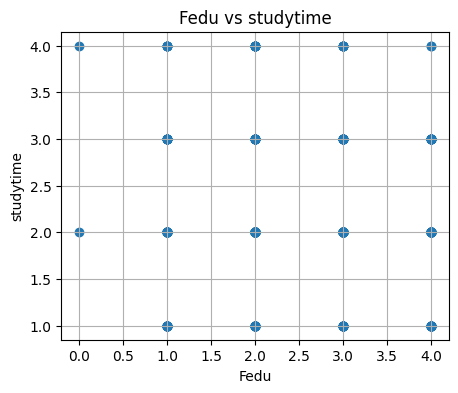

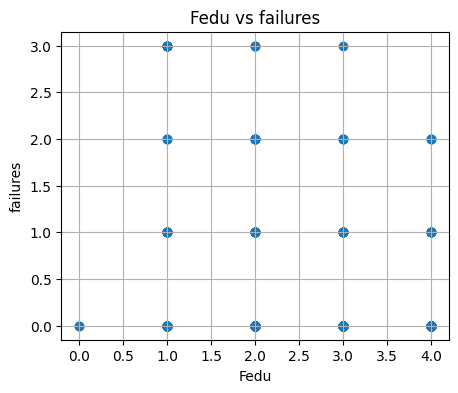

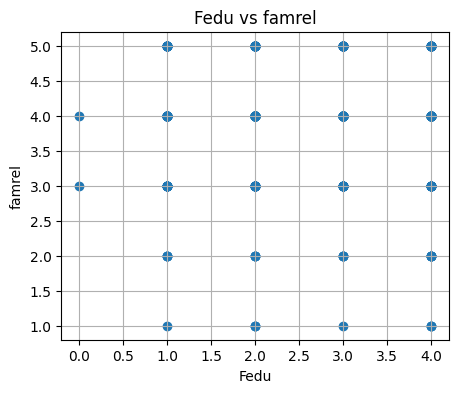

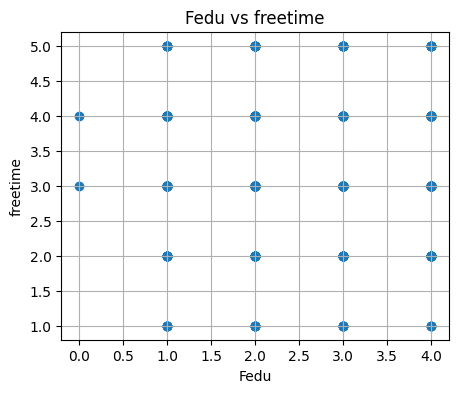

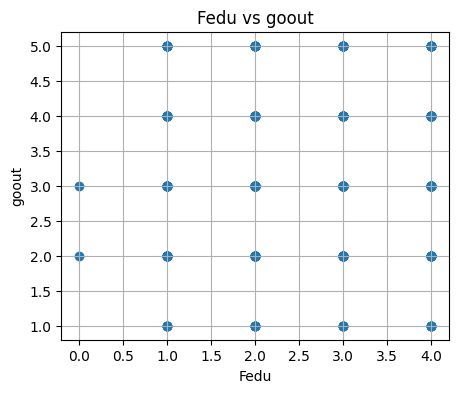

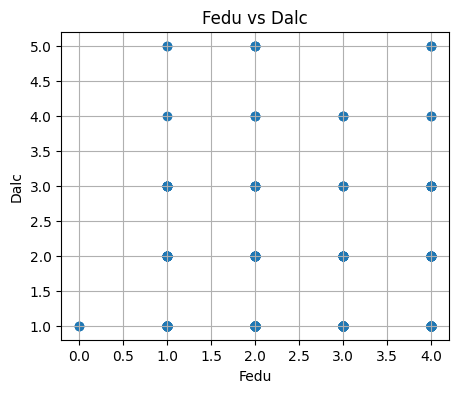

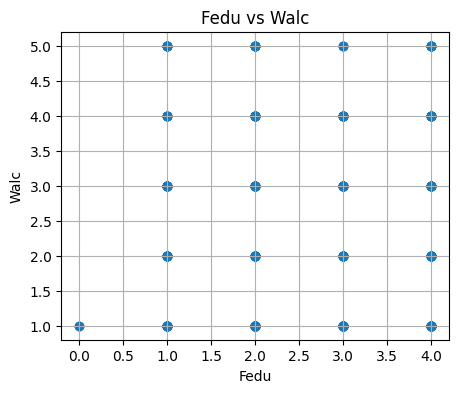

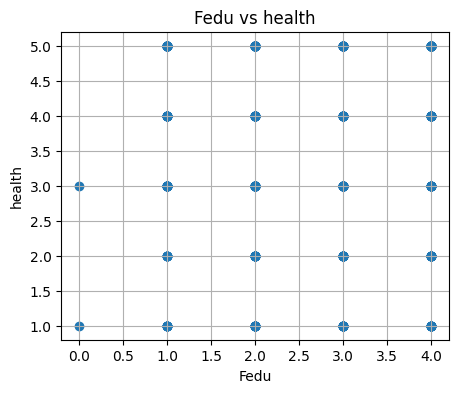

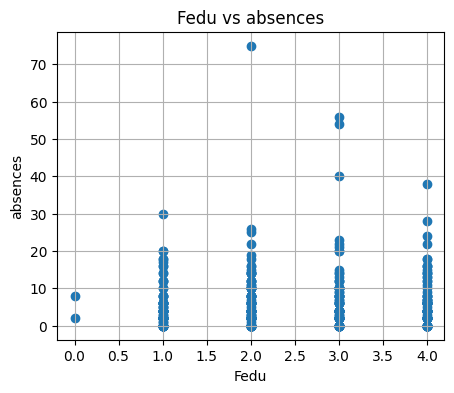

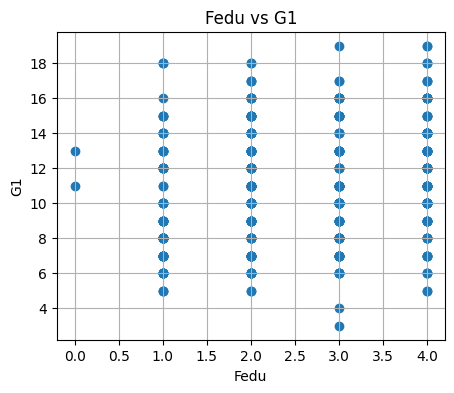

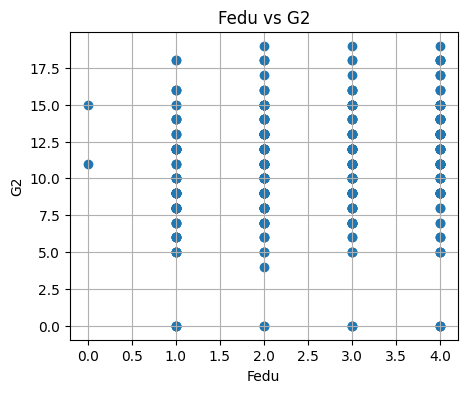

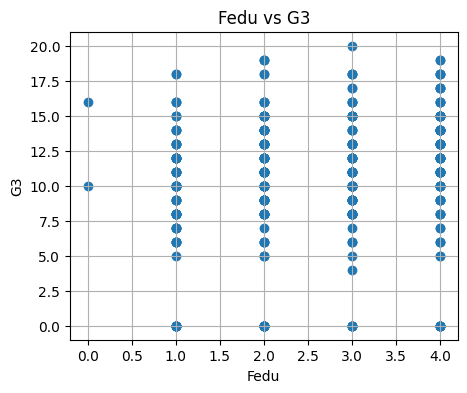

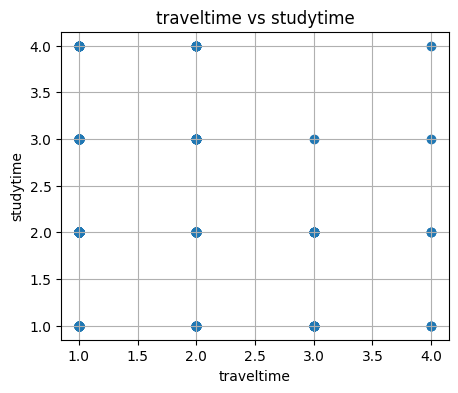

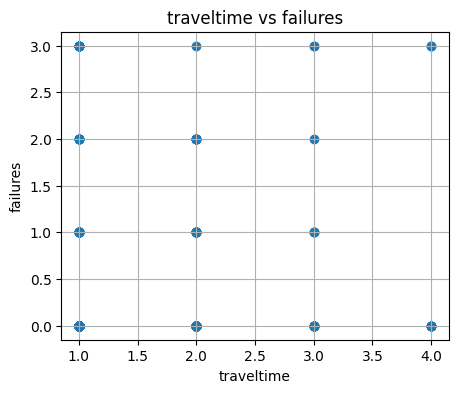

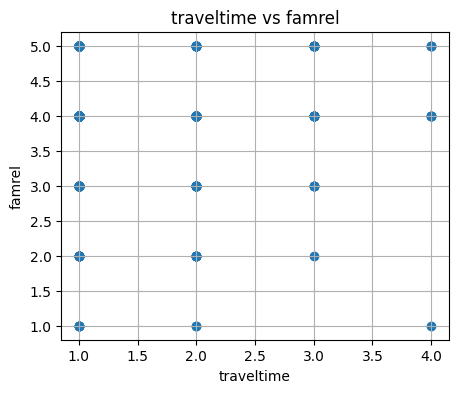

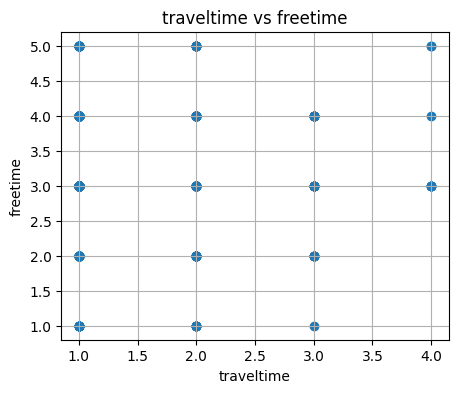

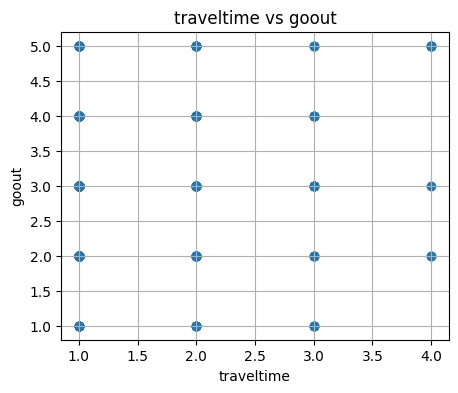

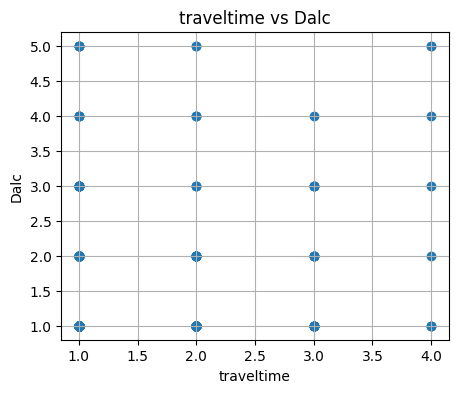

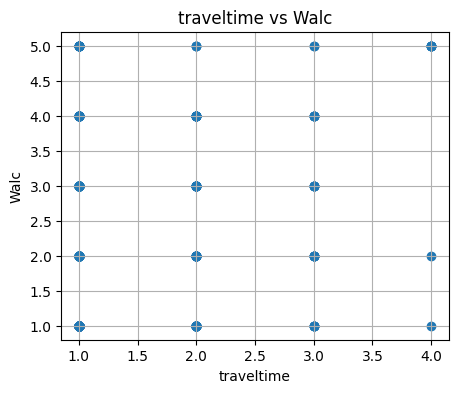

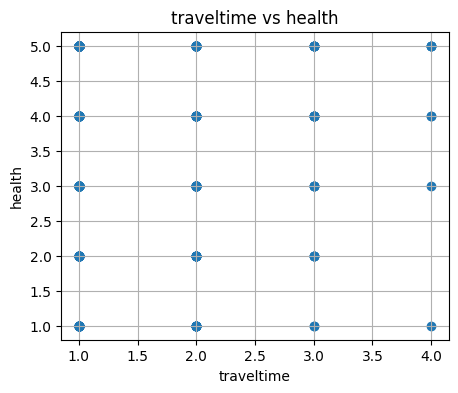

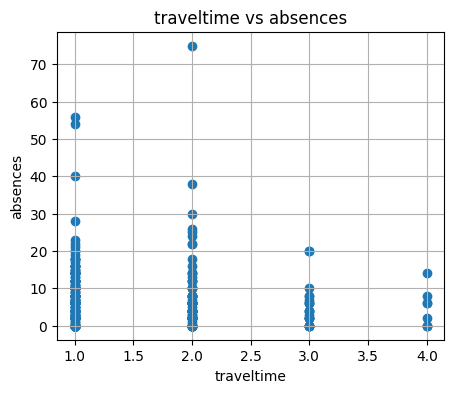

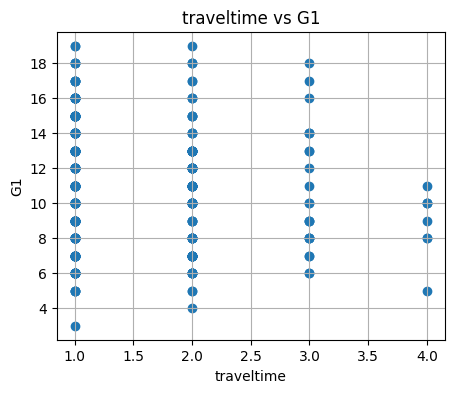

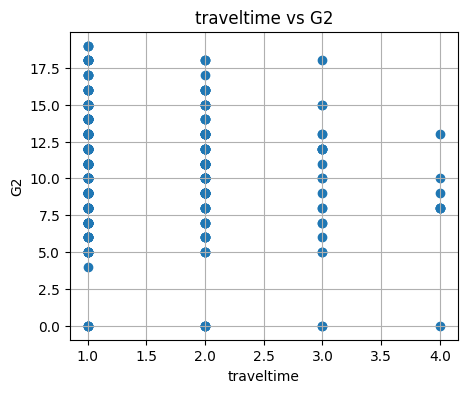

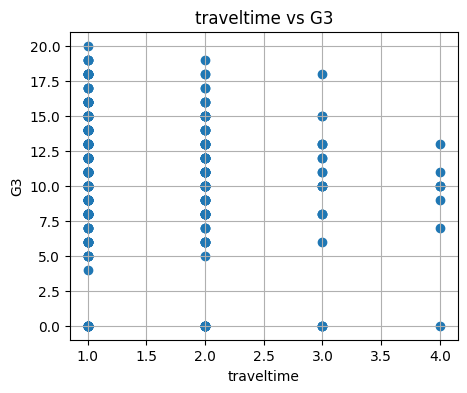

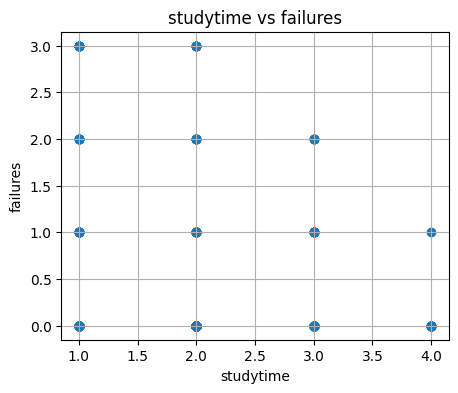

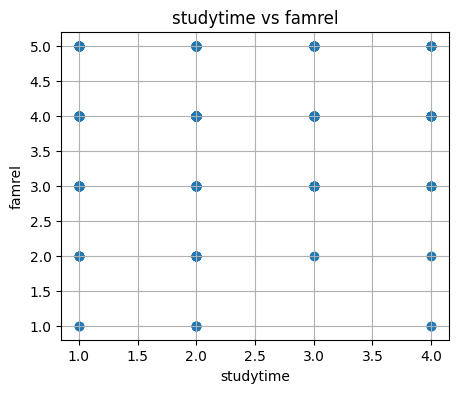

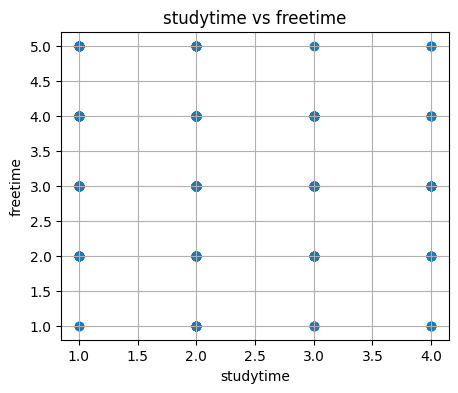

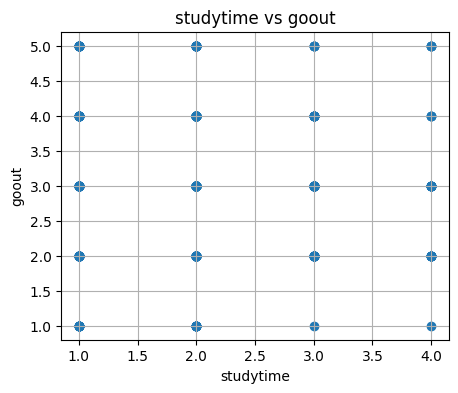

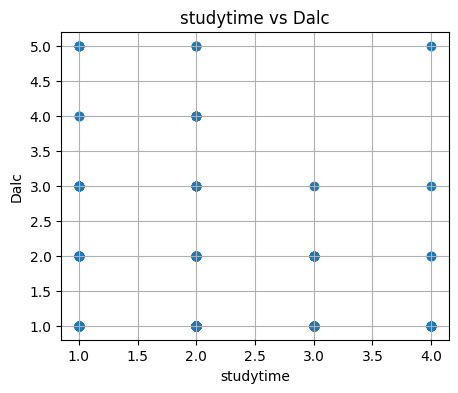

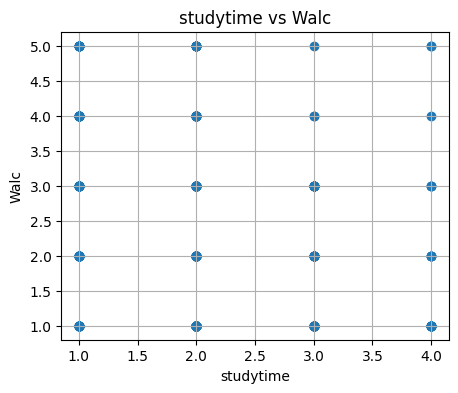

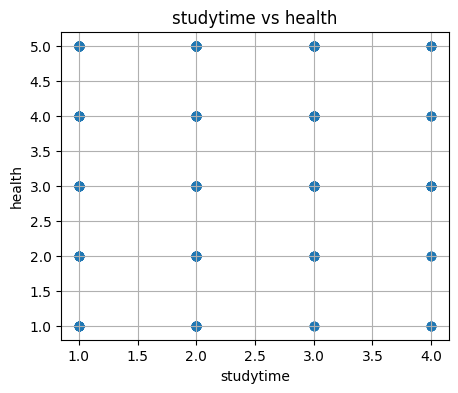

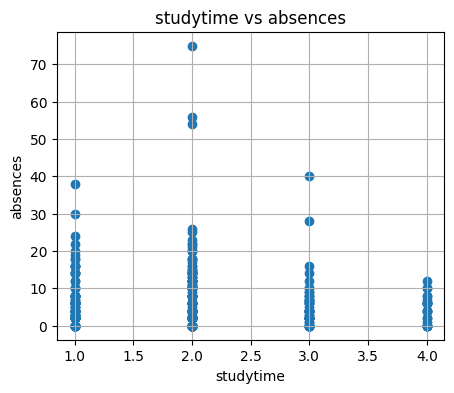

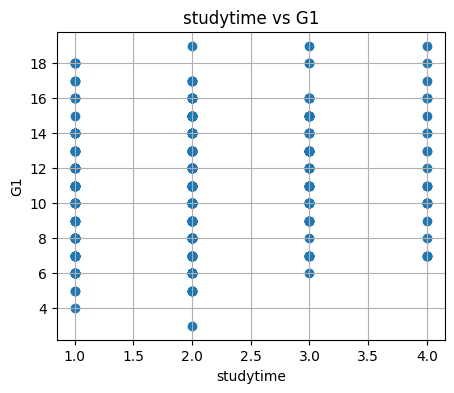

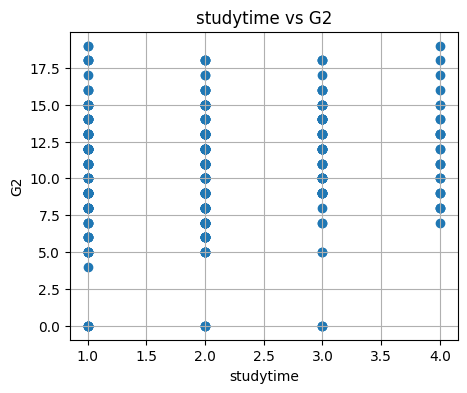

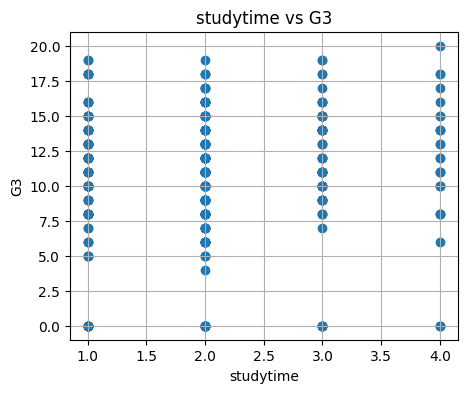

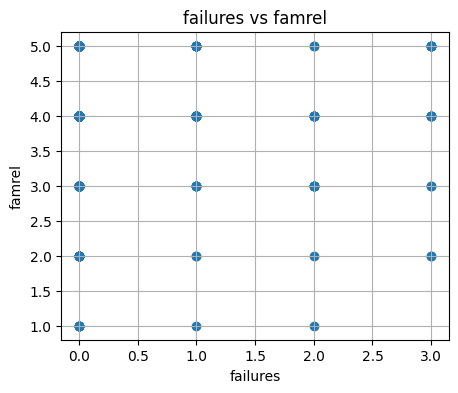

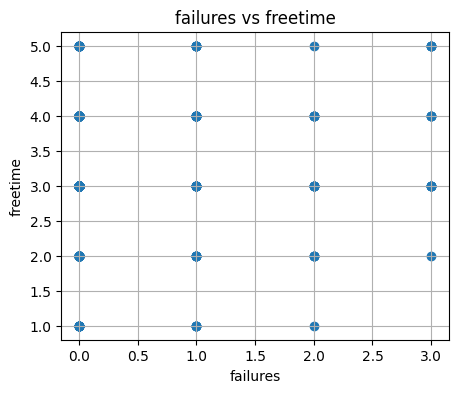

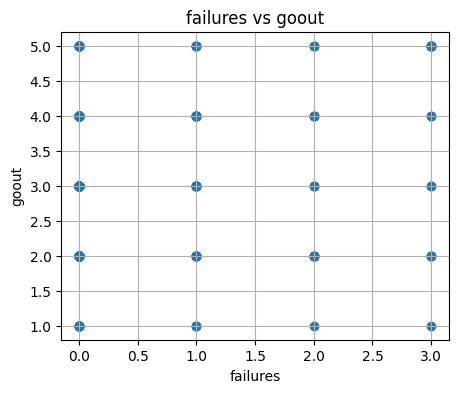

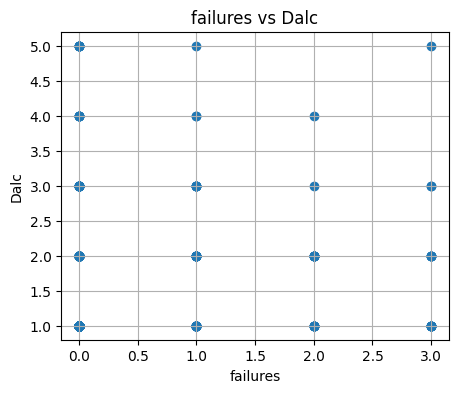

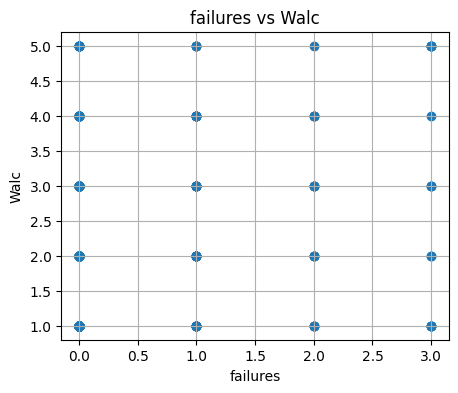

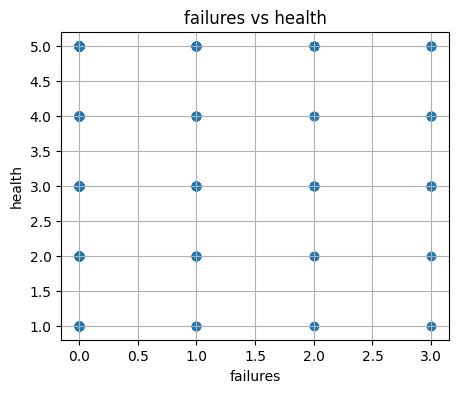

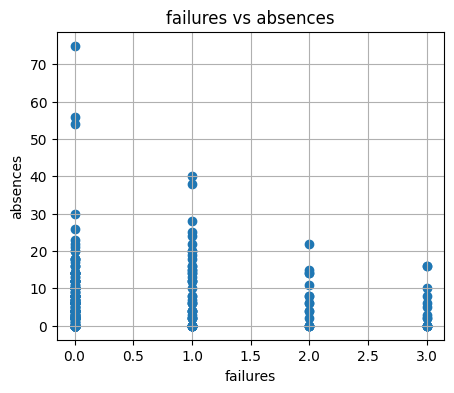

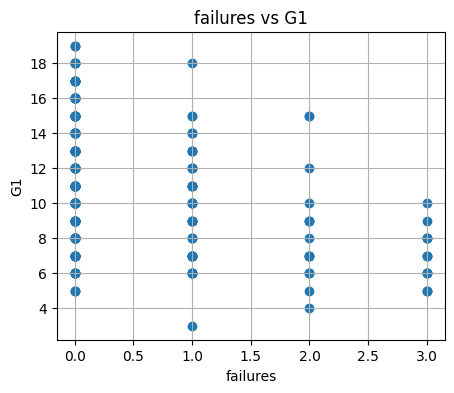

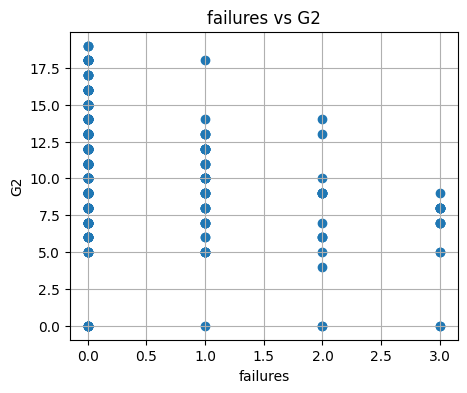

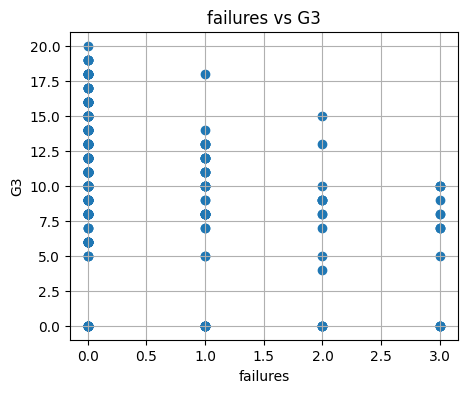

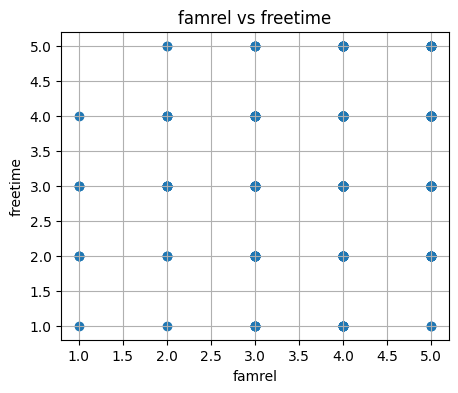

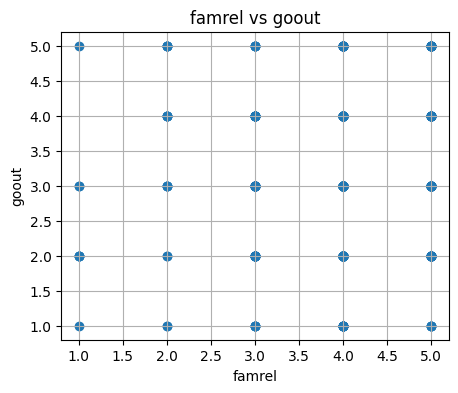

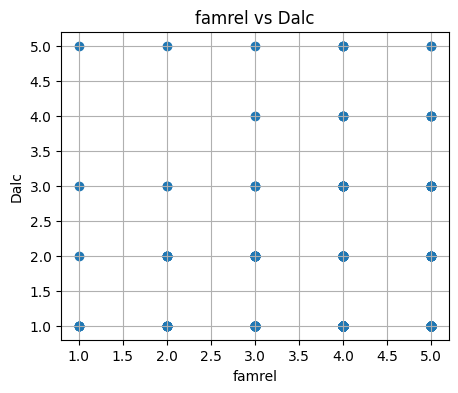

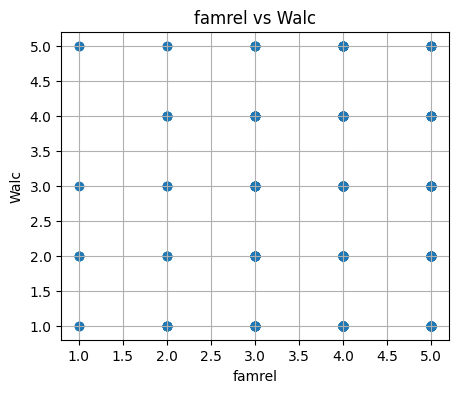

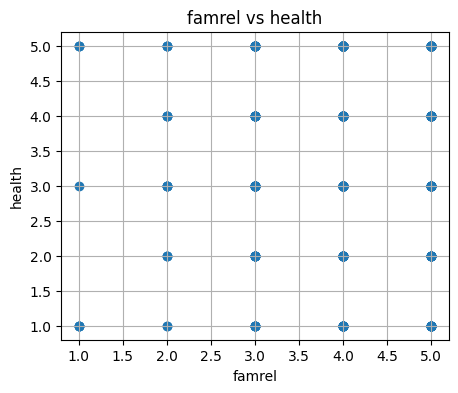

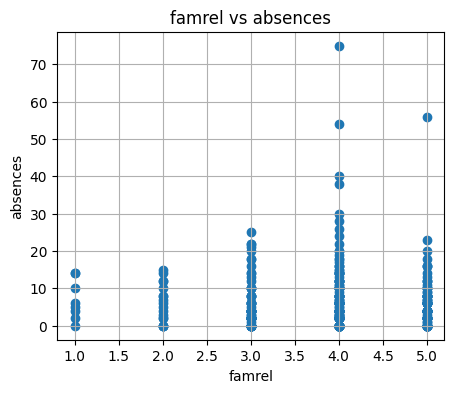

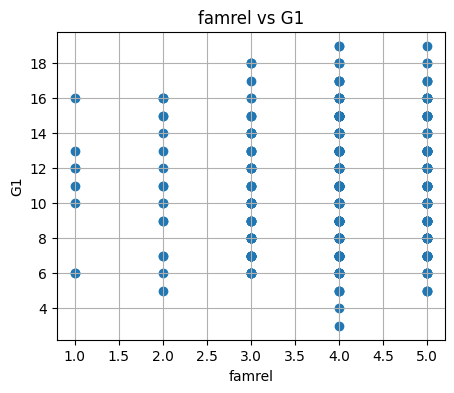

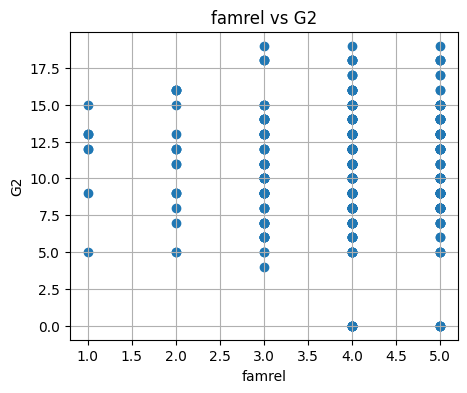

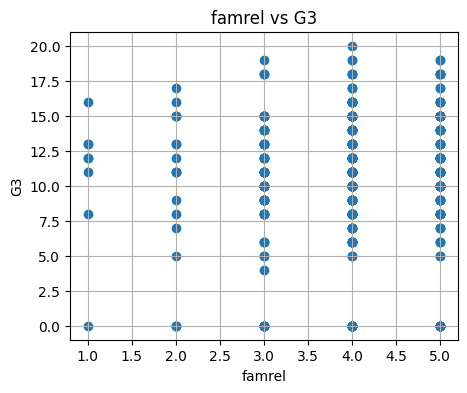

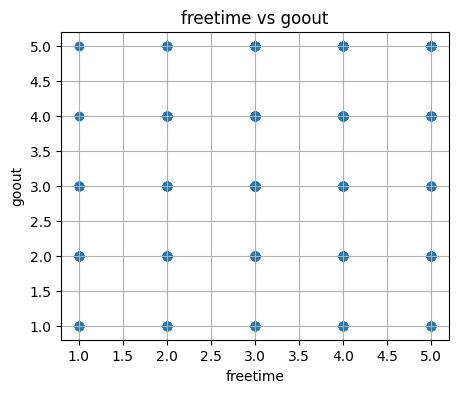

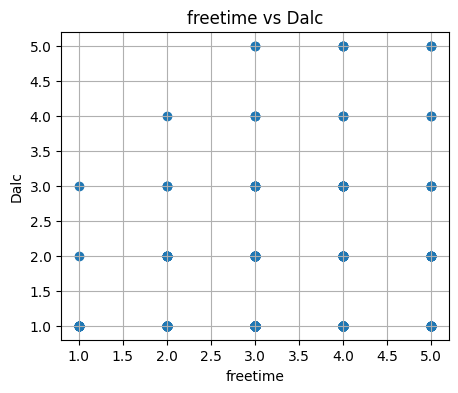

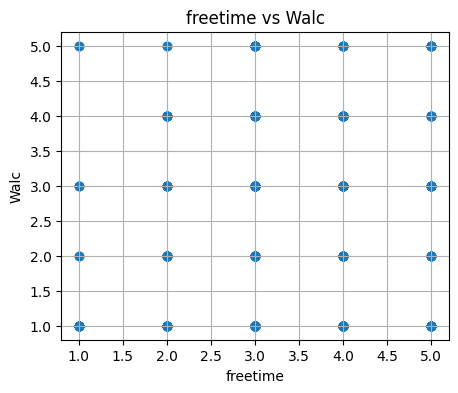

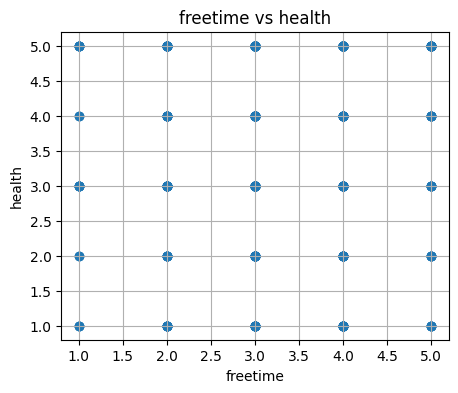

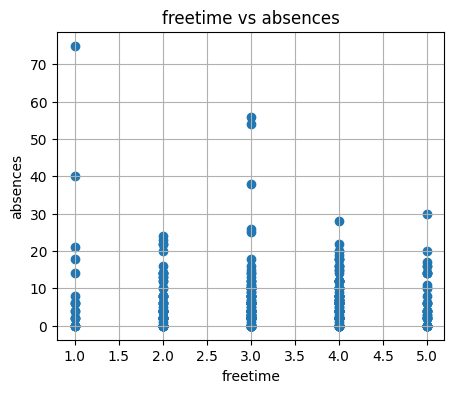

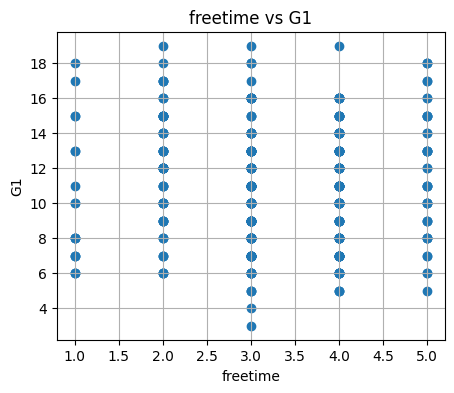

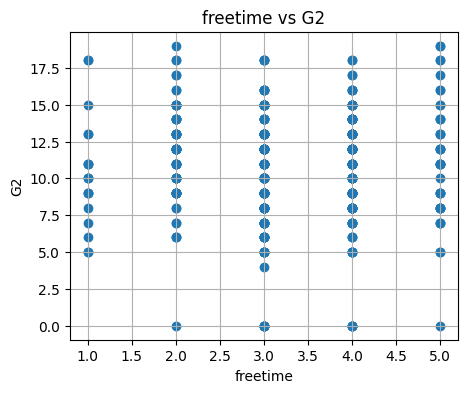

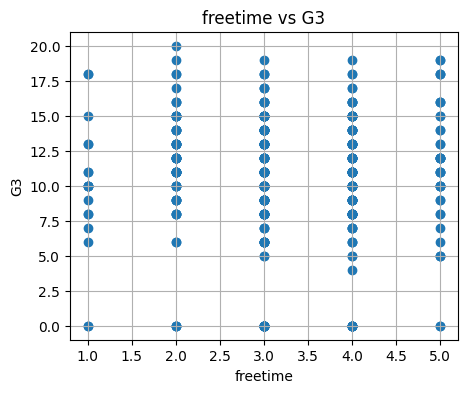

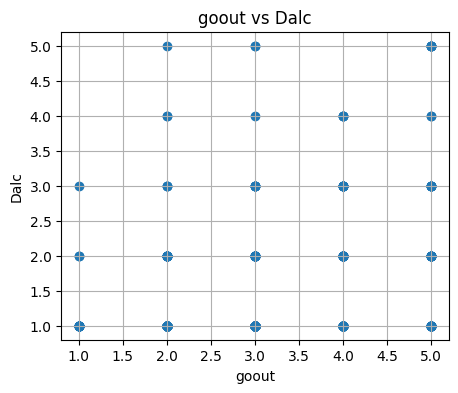

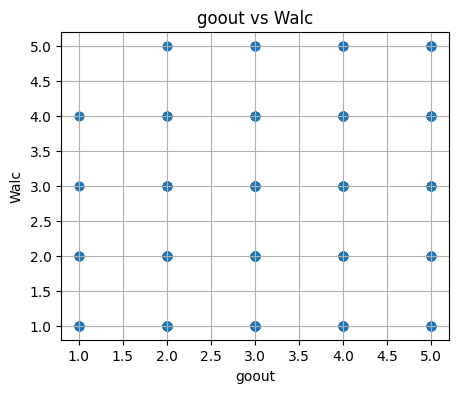

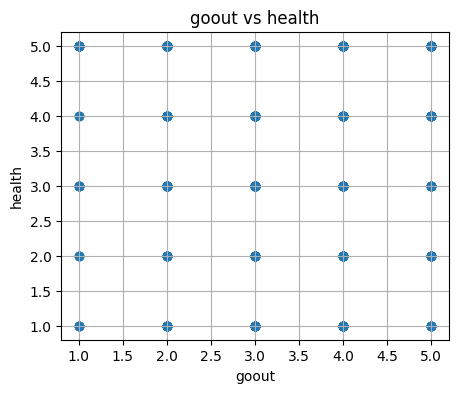

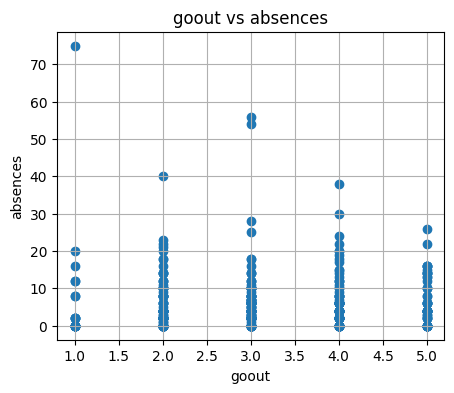

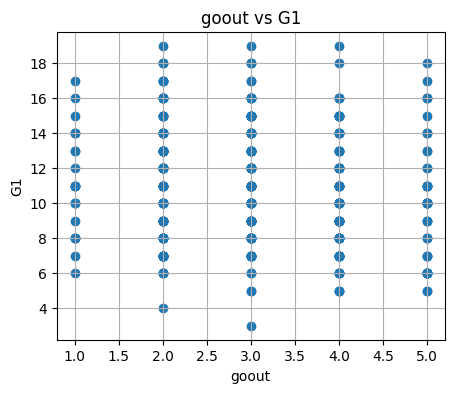

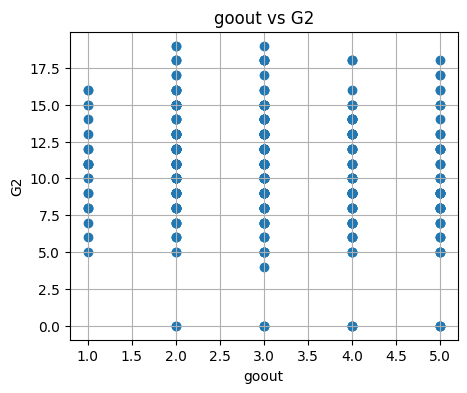

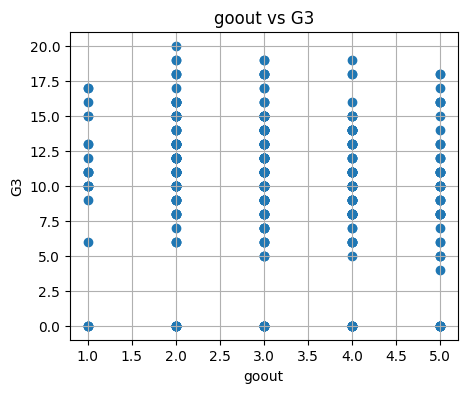

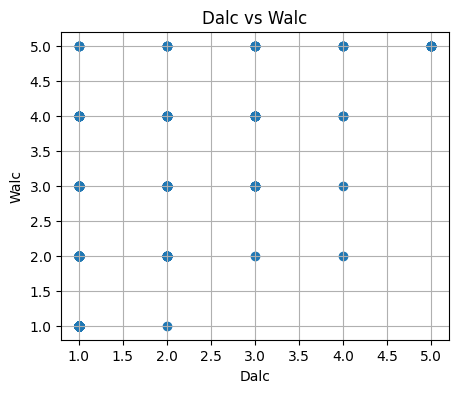

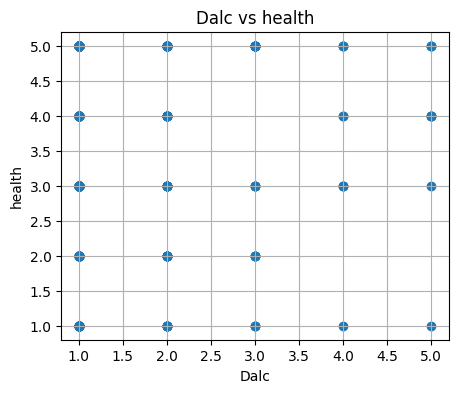

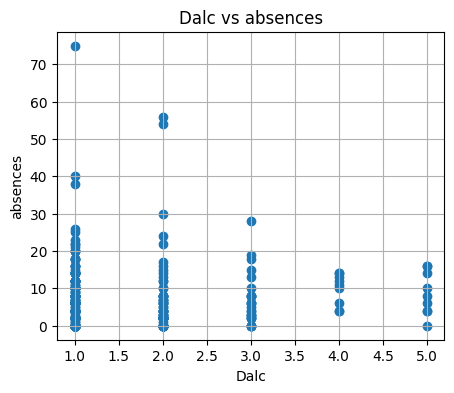

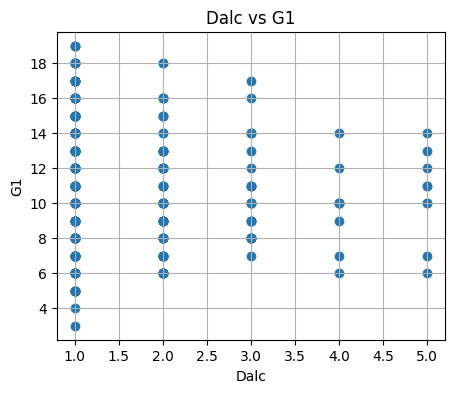

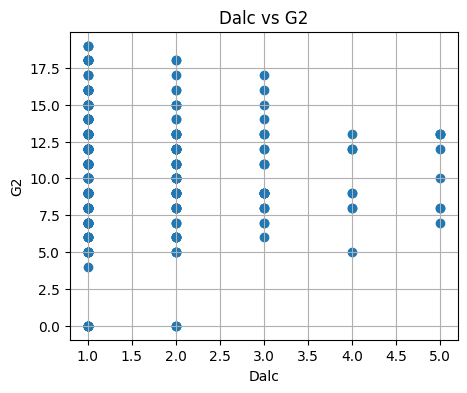

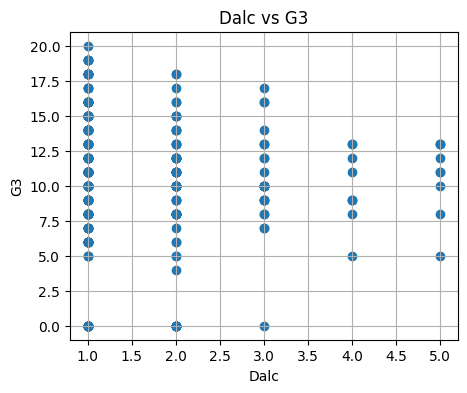

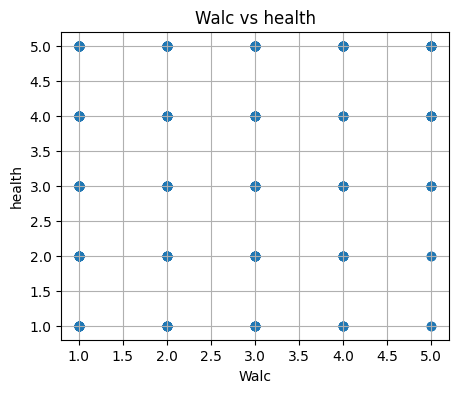

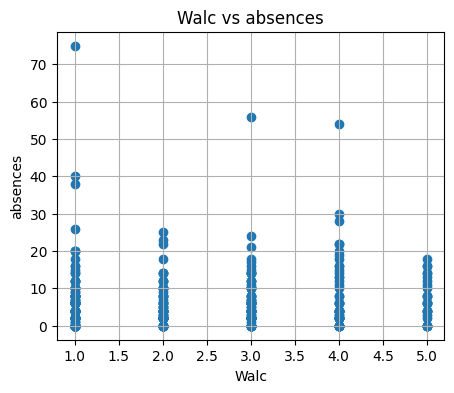

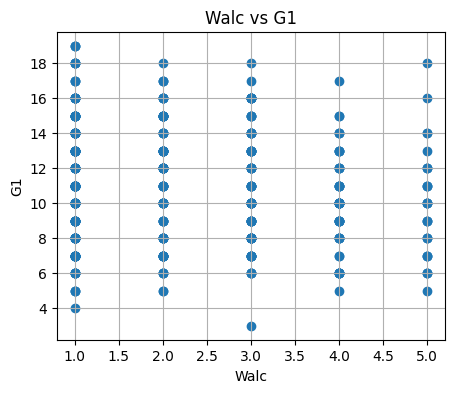

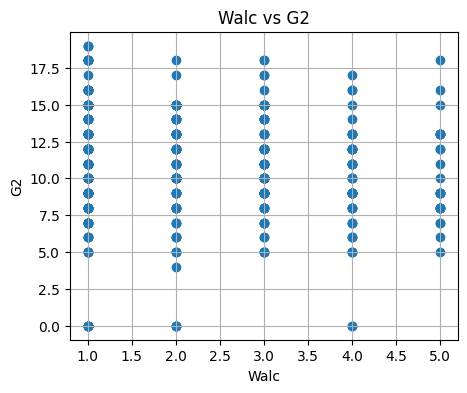

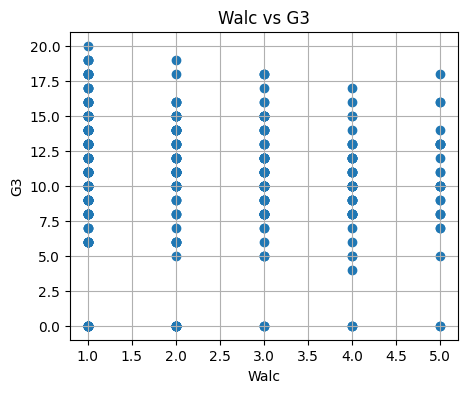

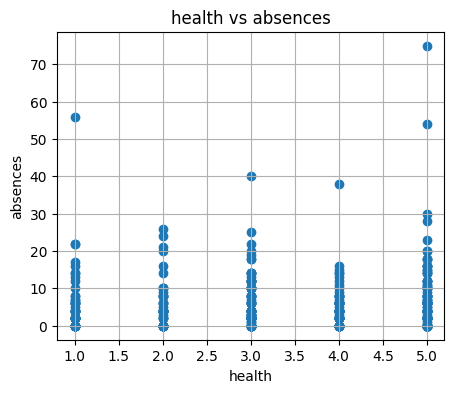

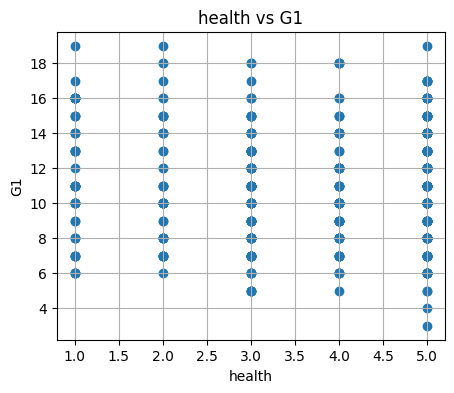

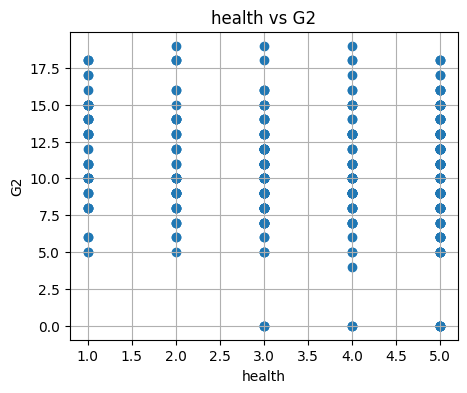

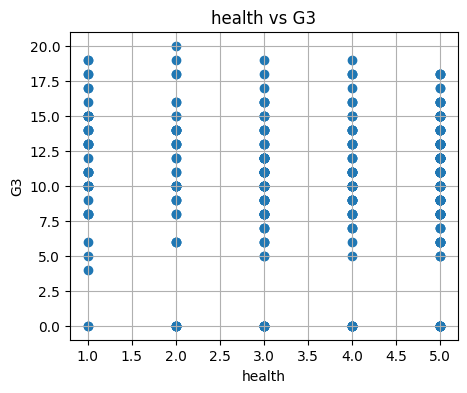

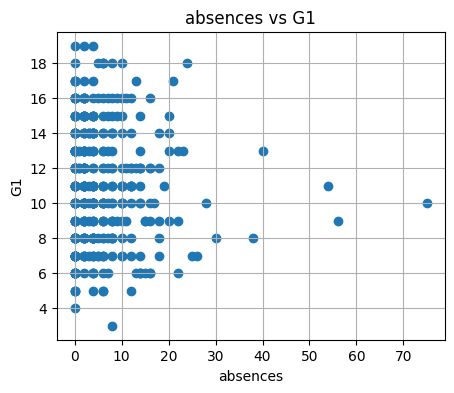

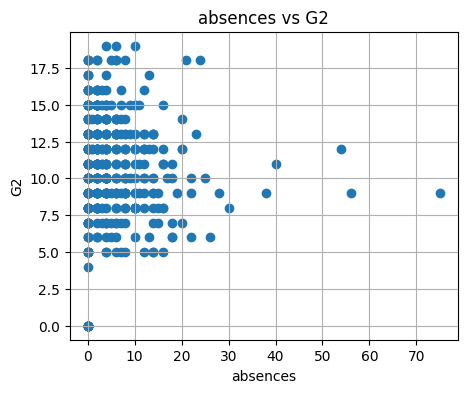

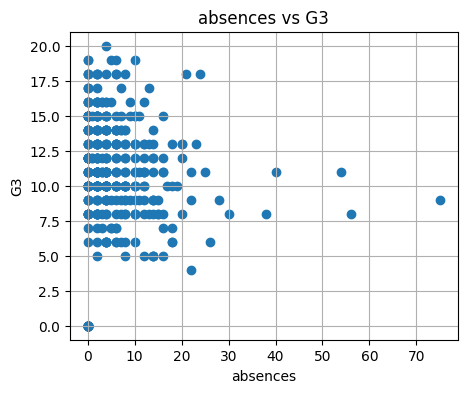

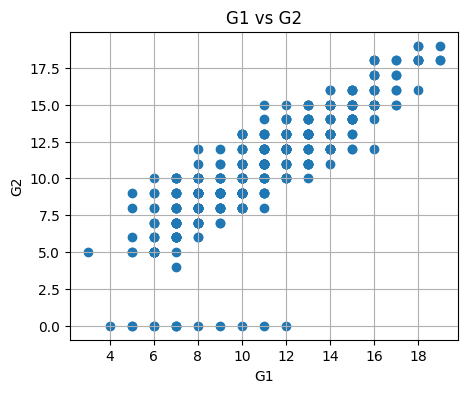

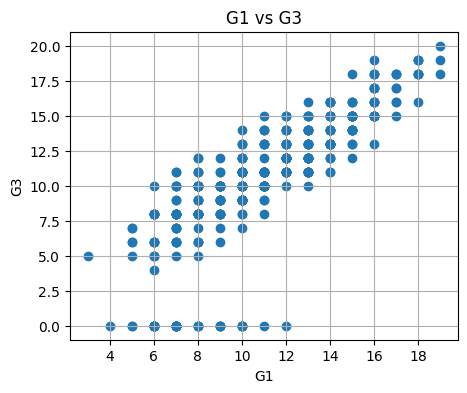

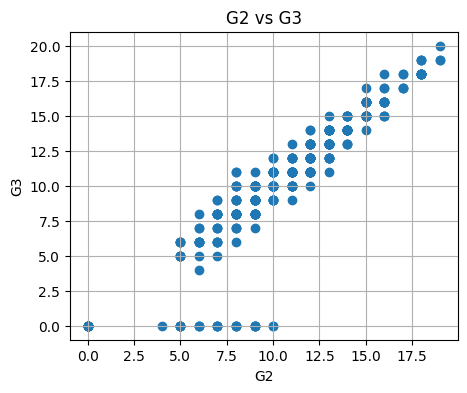

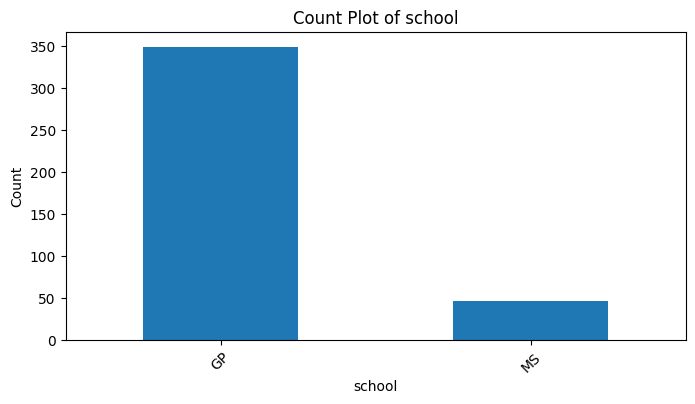

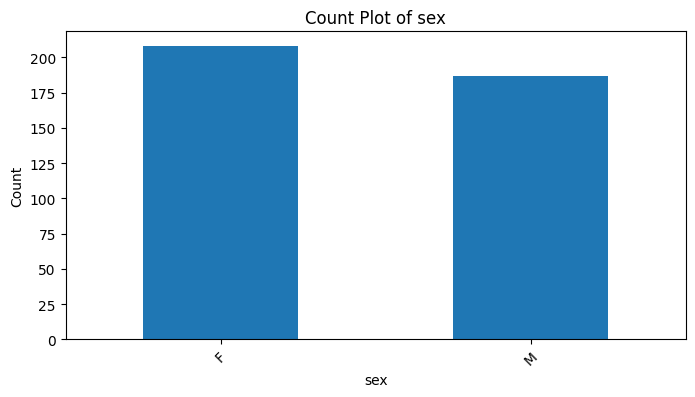

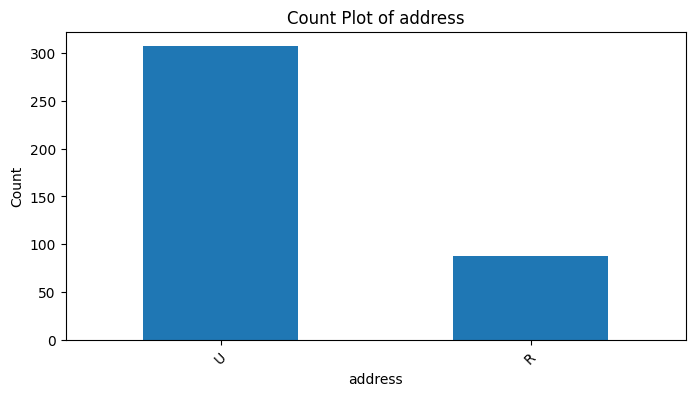

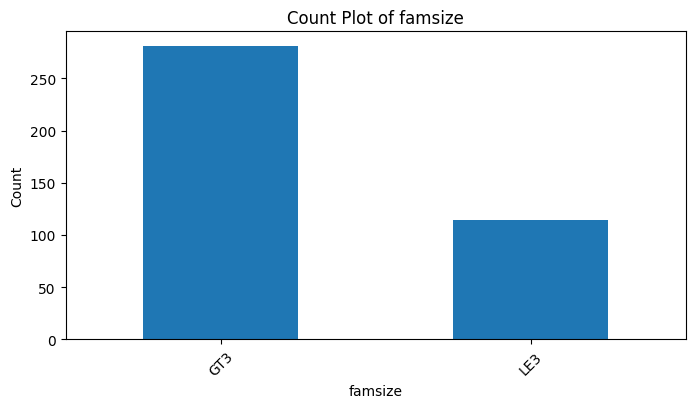

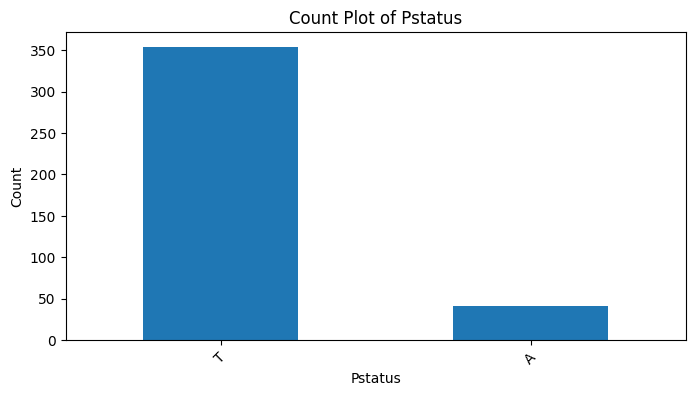

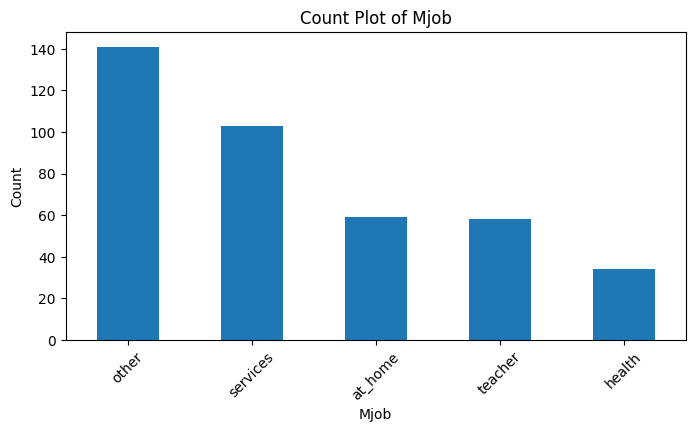

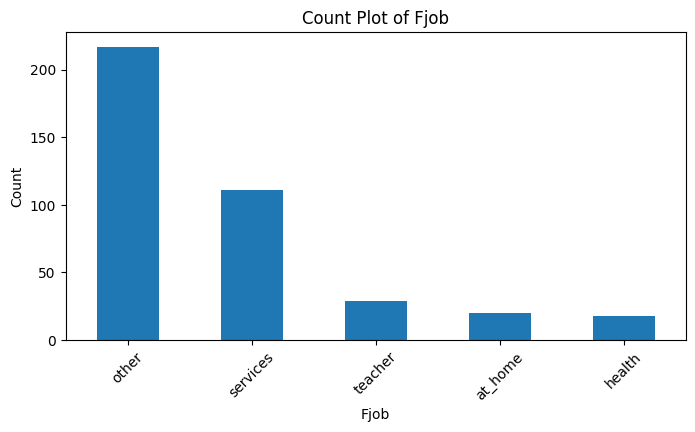

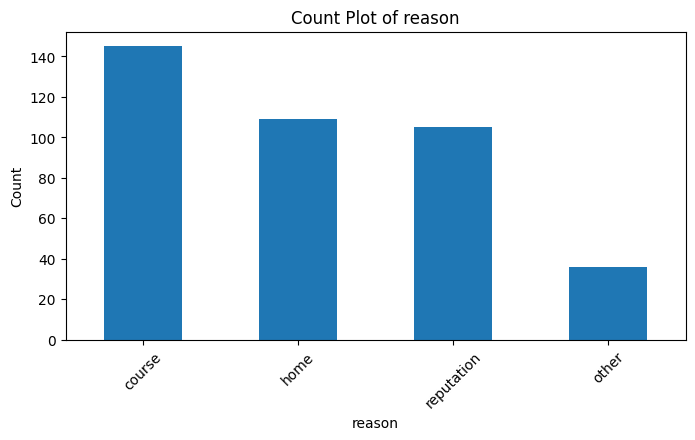

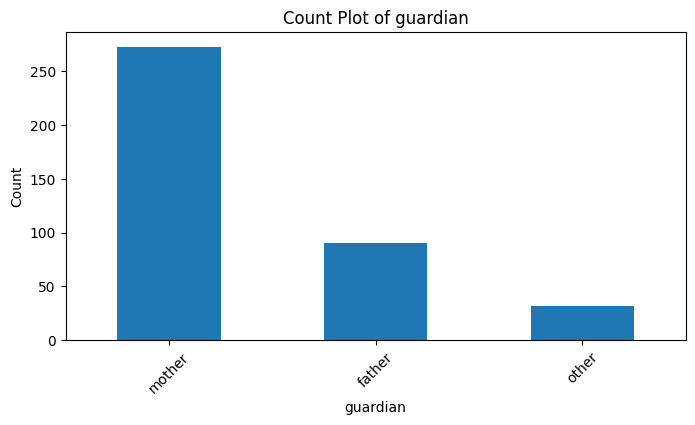

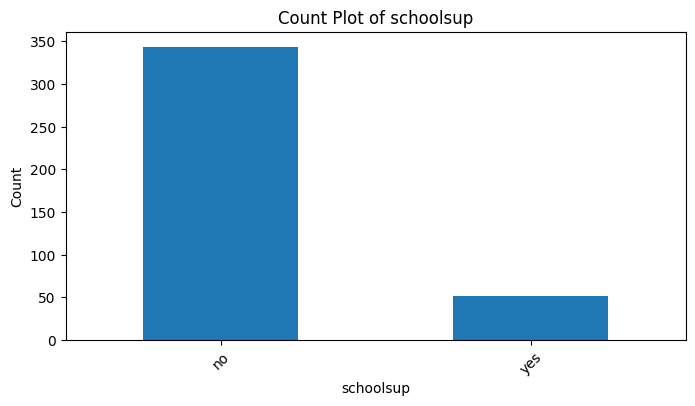

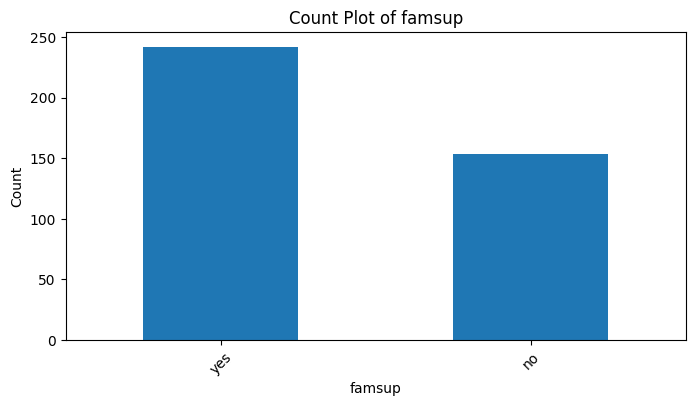

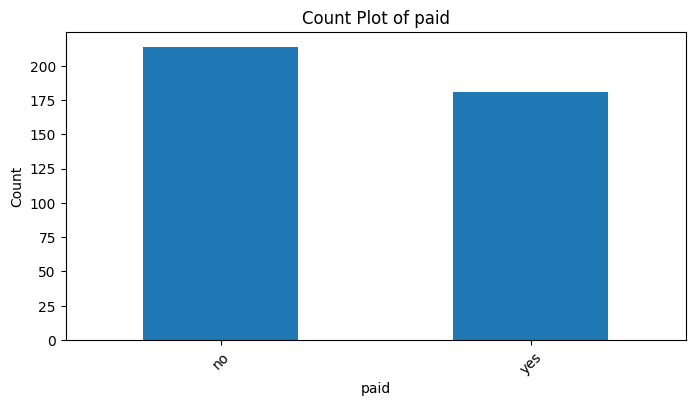

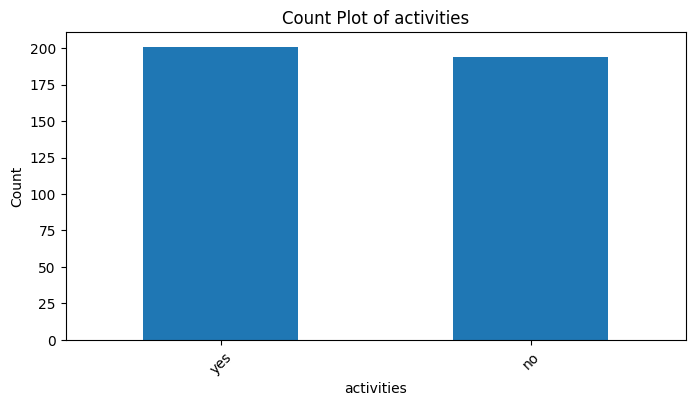

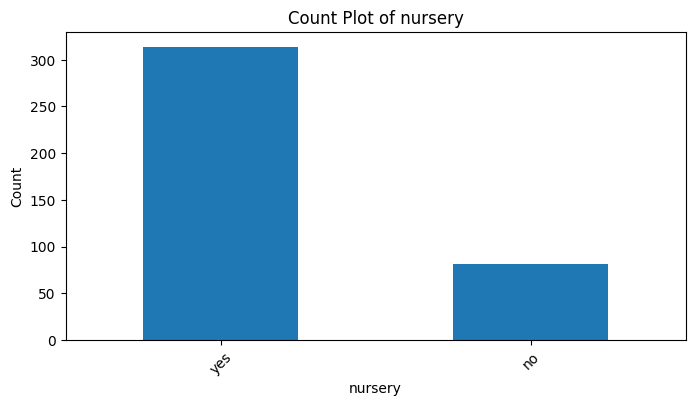

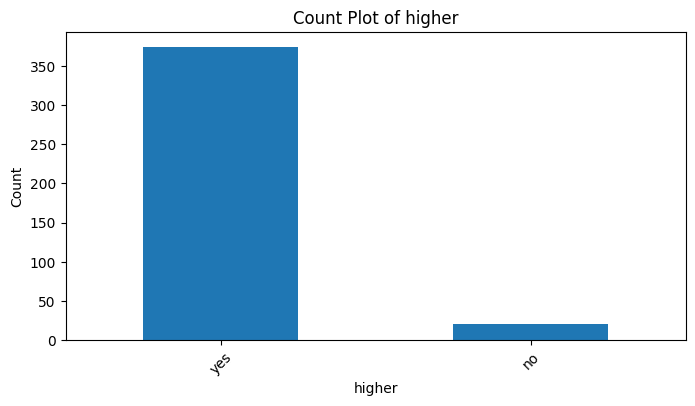

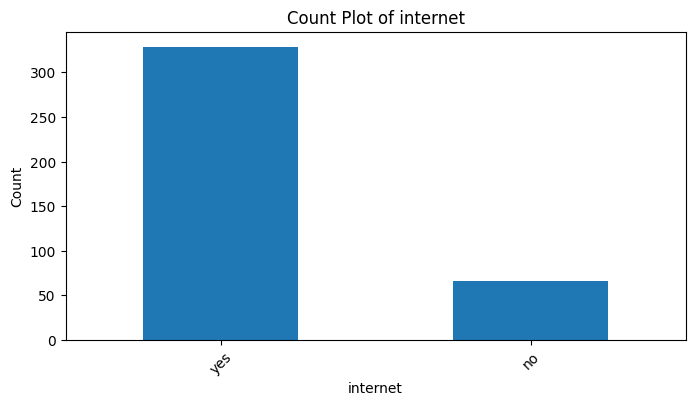

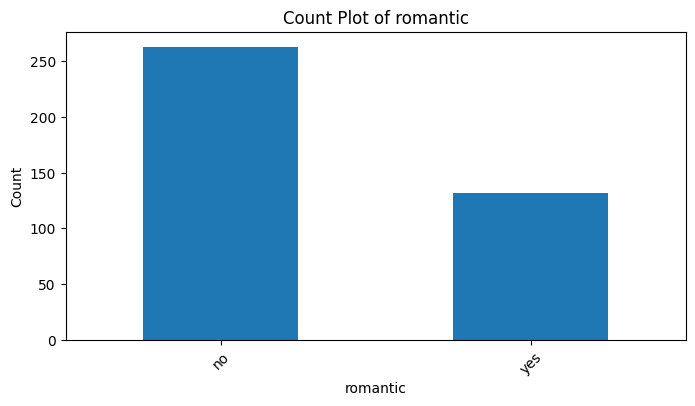


EDA COMPLETED SUCCESSFULLY!


In [1]:
# ============================
# COMPLETE EDA IN A SINGLE CELL
# ============================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load Dataset
df = pd.read_csv("/kaggle/input/datasets/sartajhuccain/asdfghjkl/student_data.csv")

# Basic Information
print("="*50)
print("FIRST 5 ROWS")
print(df.head())

print("\n" + "="*50)
print("LAST 5 ROWS")
print(df.tail())

print("\n" + "="*50)
print("SHAPE:", df.shape)

print("\n" + "="*50)
print("COLUMNS:")
print(df.columns.tolist())

print("\n" + "="*50)
print("DATA TYPES")
print(df.dtypes)

print("\n" + "="*50)
print("MISSING VALUES")
print(df.isnull().sum())

print("\n" + "="*50)
print("DUPLICATE ROWS:", df.duplicated().sum())

print("\n" + "="*50)
print("DESCRIPTIVE STATISTICS")
print(df.describe(include="all"))

# Numeric and Categorical Columns
num_cols = df.select_dtypes(include=np.number).columns
cat_cols = df.select_dtypes(include="object").columns

# Mean, Median, Std
if len(num_cols) > 0:
    print("\nMEAN")
    print(df[num_cols].mean())

    print("\nMEDIAN")
    print(df[num_cols].median())

    print("\nSTANDARD DEVIATION")
    print(df[num_cols].std())

# Histograms
for col in num_cols:
    plt.figure(figsize=(6,4))
    plt.hist(df[col], bins=20)
    plt.title(f"Histogram of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.grid(True)
    plt.show()

# Boxplots
for col in num_cols:
    plt.figure(figsize=(6,2))
    plt.boxplot(df[col], vert=False)
    plt.title(f"Boxplot of {col}")
    plt.show()

# Correlation Heatmap
if len(num_cols) > 1:
    corr = df[num_cols].corr()
    plt.figure(figsize=(8,6))
    plt.imshow(corr, interpolation='nearest')
    plt.colorbar()
    plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
    plt.yticks(range(len(corr.columns)), corr.columns)

    for i in range(len(corr.columns)):
        for j in range(len(corr.columns)):
            plt.text(j, i, round(corr.iloc[i, j], 2),
                     ha='center', va='center', fontsize=8)

    plt.title("Correlation Heatmap")
    plt.show()

# Scatter Plots
for i in range(len(num_cols)):
    for j in range(i + 1, len(num_cols)):
        plt.figure(figsize=(5,4))
        plt.scatter(df[num_cols[i]], df[num_cols[j]])
        plt.xlabel(num_cols[i])
        plt.ylabel(num_cols[j])
        plt.title(f"{num_cols[i]} vs {num_cols[j]}")
        plt.grid(True)
        plt.show()

# Bar Charts for Categorical Columns
for col in cat_cols:
    plt.figure(figsize=(8,4))
    df[col].value_counts().plot(kind="bar")
    plt.title(f"Count Plot of {col}")
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.xticks(rotation=45)
    plt.show()

print("\nEDA COMPLETED SUCCESSFULLY!")


In [4]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Load dataset
df = pd.read_csv("/kaggle/input/datasets/sartajhuccain/asdfghjkl/student_data.csv")

# Encode categorical columns
for col in df.select_dtypes(include="object").columns:
    df[col] = LabelEncoder().fit_transform(df[col].astype(str))

# Use the last column as the target
X = df.iloc[:, :-1]
y = df.iloc[:, -1]

# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)

# Predict
y_pred = model.predict(X_test)

# Evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)  # Compute RMSE manually
r2 = r2_score(y_test, y_pred)

print("===== Model Evaluation =====")
print("MAE  :", mae)
print("MSE  :", mse)
print("RMSE :", rmse)
print("R2 Score :", r2)

===== Model Evaluation =====
MAE  : 1.4954750100522765
MSE  : 5.03239410886674
RMSE : 2.2432998258963823
R2 Score : 0.7545777855043501
